# BridgePulse — מחברת ניתוח משוחזרת
המחברת שוחזרה מהפונקציות ושלבי הניתוח שבנינו בשיחה, ולא מגיבוי של התאים שנמחקו. הרץ לפי הסדר עם kernel בשם Python (BridgePulse).

קובץ H5 נפתח לקריאה בלבד. אין סינון, נרמול, מילוי חסרים, השמטת חיישנים או כתיבת דאטה מעובד. התווית הבינארית היא מיפוי בזיכרון: 0 למצב בסיס ללא נזק יזום, 1 לנזק יזום. אין כאן מודל מאומן. תחומי התדר הם בחירה חקרנית; מצבי הניסוי המקוריים נשמרים בתוצאות.


In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import skew, kurtosis
from scipy.integrate import trapezoid

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/raw/Rt345Bridge.h5").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside BridgePulse")
file_path = str(ROOT / "data/raw/Rt345Bridge.h5")
STATE_LABELS = {"baseline_1": 0, "baseline_2": 0,
                **{f"damage_{i}": 1 for i in range(1, 7)}}
SENSOR = "A15"
AXIS = "z"
print("Python:", sys.executable)
print("Data:", file_path)


Python: C:\project_ML\BridgePulse\.venv\Scripts\python.exe
Data: C:\project_ML\BridgePulse\data\raw\Rt345Bridge.h5


## 1. מבנה הקובץ והתיוג המקורי

In [2]:
with h5py.File(file_path, "r") as file:
    print("Bridge:", file.attrs.get("structure_name"))
    for state in STATE_LABELS:
        group = file[state]
        print("\n", state, dict(group.attrs))
        print("Acceleration recordings:", list(group["acceleration"]))
        print("Strain recordings:", list(group["strain"]))
    sensors = list(file["baseline_1/acceleration/test_1"])
    print("\nAcceleration sensors:", len(sensors), sensors)
    print("Strain sensors:", len(file["baseline_1/strain/center_lane"]))


Bridge: Route 345 Bridge over Big Sucker Brook

 baseline_1 {'damage_location': 'N/A', 'damage_severity': 'N/A', 'damage_state': 'Baseline 1 - As-is condition of bridge prior to imposed damage', 'damage_type': 'None'}
Acceleration recordings: ['test_1', 'test_2', 'test_3']
Strain recordings: ['center_lane', 'east_lane', 'west_lane']

 baseline_2 {'damage_location': 'N/A', 'damage_severity': 'N/A', 'damage_state': 'Baseline 2 - Hydraulic jack removed from rocker bearing', 'damage_type': 'None'}
Acceleration recordings: ['test_1', 'test_2', 'test_3']
Strain recordings: ['center_lane', 'east_lane', 'west_lane']

 damage_1 {'damage_location': 'Stringer 5 expansion bearing', 'damage_severity': 'Approximately 3 mm', 'damage_state': 'Damage 1 - Upward displacement of eastmost rocker bearing by approximately 3 mm', 'damage_type': 'Differential settlement or seizure at expansion bearing'}
Acceleration recordings: ['test_1', 'test_2', 'test_3']
Strain recordings: ['center_lane', 'east_lane', 'we

## 2. קריאת אות ותיוג בינארי בזיכרון

In [3]:
def binary_label(state):
    if state not in STATE_LABELS:
        raise ValueError(f'Unknown state: {state}')
    return STATE_LABELS[state]

def read_acceleration(file_path, state, test, sensor, axis):
    with h5py.File(file_path, 'r') as file:
        group = file[f'{state}/acceleration/{test}/{sensor}']
        return group[axis][...], dict(group.attrs)

def recording_signals(file_path, sensor='A15', axis='z'):
    with h5py.File(file_path,'r') as file:
        for state,label in STATE_LABELS.items():
            for test in sorted(file[state]['acceleration']):
                group=file[f'{state}/acceleration/{test}/{sensor}']
                x=group[axis][...].reshape(-1)
                fs=float(np.asarray(group.attrs['sample_rate']).item())
                if not np.isfinite(x).all():raise ValueError(f'Invalid values: {state}/{test}')
                yield state,test,label,x,fs

Shape: (1, 11522) dtype: float64 sample rate: 128.0
Label: 0 metadata: {'internal_sample_rate': array([512.]), 'location': 'Stringer 3 at 7.84 m from rocker bearing', 'name': 'A15', 'position': array([7.84    , 4.26    , 0.238608]), 'sample_rate': array([128.]), 'type': 'LIS2L02AL dual-axis MEMS accelerometer', 'unit': 'm/s^2'}


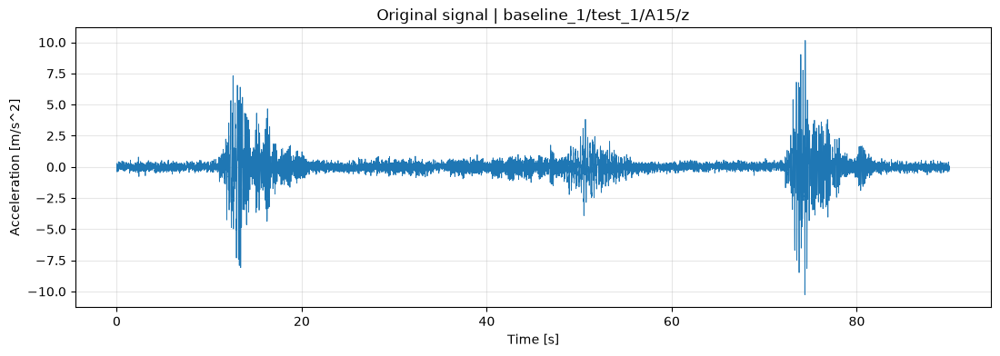

In [4]:
state = "baseline_1"
data, metadata = read_acceleration(file_path, state, "test_1", SENSOR, AXIS)
fs = float(np.asarray(metadata["sample_rate"]).item())
label = binary_label(state)
print("Shape:", data.shape, "dtype:", data.dtype, "sample rate:", fs)
print("Label:", label, "metadata:", metadata)
signal = data.reshape(-1)
time = np.arange(signal.size) / fs
fig, ax = plt.subplots(figsize=(13,4))
ax.plot(time, signal, lw=0.6)
ax.set(xlabel="Time [s]", ylabel="Acceleration [m/s^2]", title=f"Original signal | {state}/test_1/{SENSOR}/{AXIS}")
ax.grid(alpha=0.3); plt.show()


## 3. ערכים חסרים וערוצים קבועים
אפס אינו אוטומטית חסר. הסריקה מתעדת בעיות בלבד, ללא תיקון. S11 ו־S13 במעוותים ו־A14 ב־damage_6 נמצאו קבועים בבדיקות הקודמות; הם אינם מוסרים כאן.


In [5]:
def check_missing_values(data):
    x = np.asarray(data)
    invalid = ~np.isfinite(x)
    return {'total_values':x.size,'nan_count':int(np.isnan(x).sum()),
            'inf_count':int(np.isinf(x).sum()),
            'invalid_percent':100*float(invalid.mean()) if x.size else 0,
            'invalid_positions':np.argwhere(invalid)}

In [6]:
print("Selected signal:", check_missing_values(data))
quality_rows = []
with h5py.File(file_path, "r") as file:
    for state in STATE_LABELS:
        for kind in ("acceleration", "strain"):
            def inspect(name, obj):
                if isinstance(obj, h5py.Dataset):
                    values = obj[...]
                    report = check_missing_values(values)
                    quality_rows.append({"state": state, "kind": kind, "path": obj.name,
                        "nan": report["nan_count"], "inf": report["inf_count"],
                        "constant": bool(values.size and np.isfinite(values).all() and np.ptp(values)==0)})
            file[state][kind].visititems(inspect)
print("Measurement arrays:", len(quality_rows))
print("NaN:", sum(r["nan"] for r in quality_rows), "Infinity:", sum(r["inf"] for r in quality_rows))
print("Constant arrays:", sum(r["constant"] for r in quality_rows))
for row in quality_rows:
    if row["constant"]: print(row["path"])


Selected signal: {'total_values': 11522, 'nan_count': 0, 'inf_count': 0, 'invalid_percent': 0.0, 'invalid_positions': array([], shape=(0, 2), dtype=int64)}


Measurement arrays: 1980
NaN: 0 Infinity: 0
Constant arrays: 56
/baseline_1/strain/center_lane/S11
/baseline_1/strain/center_lane/S13
/baseline_1/strain/east_lane/S11
/baseline_1/strain/east_lane/S13
/baseline_1/strain/west_lane/S11
/baseline_1/strain/west_lane/S13
/baseline_2/strain/center_lane/S11
/baseline_2/strain/center_lane/S13
/baseline_2/strain/east_lane/S11
/baseline_2/strain/east_lane/S13
/baseline_2/strain/west_lane/S11
/baseline_2/strain/west_lane/S13
/damage_1/strain/center_lane/S11
/damage_1/strain/center_lane/S13
/damage_1/strain/east_lane/S11
/damage_1/strain/east_lane/S13
/damage_1/strain/west_lane/S11
/damage_1/strain/west_lane/S13
/damage_2/strain/center_lane/S11
/damage_2/strain/center_lane/S13
/damage_2/strain/east_lane/S11
/damage_2/strain/east_lane/S13
/damage_2/strain/west_lane/S11
/damage_2/strain/west_lane/S13
/damage_3/strain/center_lane/S11
/damage_3/strain/center_lane/S13
/damage_3/strain/east_lane/S11
/damage_3/strain/east_lane/S13
/damage_3/strain/west_la

## 4. ספקטרום Welch והשוואה בינארית
Welch מבוסס על FFT במקטעים חופפים. 16 שניות ו־50% חפיפה הם פרמטרי ניתוח בלבד. הקו הוא חציון הספקטרומים והשטח השקוף הוא אחוזונים 25–75, לא רווח סמך. כל הקלטה מקבלת משקל שווה: 6 בסיס מול 19 נזק.


In [7]:
def calculate_psd(data, fs, segment_seconds=16):
    x = np.asarray(data).squeeze()
    if x.ndim != 1 or x.size < 2 or not np.isfinite(x).all():
        raise ValueError('Expected one finite signal with at least two samples')
    if fs<=0 or segment_seconds<=0:
        raise ValueError('Sample rate and segment length must be positive')
    size=min(x.size,int(round(segment_seconds*fs)))
    if size<2:raise ValueError('Segment too short')
    return welch(x,fs=fs,window='hann',nperseg=size,noverlap=size//2,detrend=False)

def compare_binary_psd(file_path,sensor='A15',axis='z',segment_seconds=16):
    spectra={0:[],1:[]}; recordings={0:[],1:[]}; reference=None
    for state,test,label,x,fs in recording_signals(file_path,sensor,axis):
        f,p=calculate_psd(x,fs,segment_seconds)
        if reference is None:reference=f
        elif f.shape!=reference.shape or not np.allclose(f,reference):raise ValueError('Frequency grids differ')
        spectra[label].append(p);recordings[label].append(f'{state}/{test}')
        if np.ptp(x)==0:print('Constant channel retained:',state,test,sensor,axis)
    fig,ax=plt.subplots(figsize=(13,5));results={}
    for label,color,name in [(0,'tab:blue','Baseline'),(1,'tab:orange','Damage')]:
        values=np.stack(spectra[label]);median=np.median(values,axis=0)
        q25,q75=np.percentile(values,[25,75],axis=0);tiny=np.finfo(float).tiny
        ax.semilogy(reference[1:],np.maximum(median[1:],tiny),color=color,label=f'{name} n={len(values)}')
        ax.fill_between(reference[1:],np.maximum(q25[1:],tiny),np.maximum(q75[1:],tiny),color=color,alpha=.2)
        results[label]={'recordings':recordings[label],'spectra':values,'median':median,'q25':q25,'q75':q75}
    ax.set(xlabel='Frequency [Hz]',ylabel='PSD [(m/s^2)^2/Hz]',title=f'Binary comparison | {sensor}/{axis.upper()}')
    ax.legend();ax.grid(alpha=.3);fig.tight_layout();plt.show()
    return reference,results

def compare_random_sensor(file_path,axis='z',seed=None):
    common=None
    with h5py.File(file_path,'r') as file:
        for state in STATE_LABELS:
            for group in file[state]['acceleration'].values():
                available={s for s in group if axis in group[s]}
                common=available if common is None else common & available
    if not common:raise ValueError('No common sensors')
    sensor=str(np.random.default_rng(seed).choice(sorted(common)))
    print('Selected sensor:',sensor,axis)
    f,results=compare_binary_psd(file_path,sensor,axis)
    return sensor,f,results

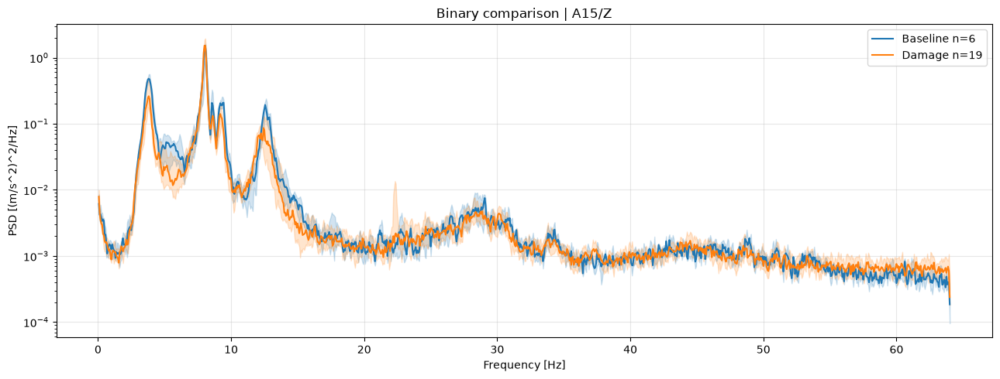

In [8]:
frequencies, spectra_results = compare_binary_psd(file_path, sensor=SENSOR, axis=AXIS)


### חיישן אקראי — תא אופציונלי
כל הרצה בוחרת חיישן משותף לכל ההקלטות. A14 עשוי להיבחר; כשל המדידה שלו אינו עדות לנזק.


In [9]:
# להסרת ההערה ולהרצה כאשר רוצים חיישן אקראי:
# random_sensor, random_frequencies, random_results = compare_random_sensor(file_path, axis=AXIS)


## 5. הספק בתחומי תדר — נקודה לכל הקלטה
המדד הוא אינטגרל ה־PSD בתדר (band power), ולא אנרגיה משולבת לאורך זמן. התחומים נבחרו לחקירה לאחר הסתכלות בגרפים ואינם תדרים שהוכחו כחשובים לחיזוי.


In [10]:
def compare_band_energy(file_path,sensor='A15',axis='z',bands=((4,8),(8,14),(25,35),(55,64))):
    rows=[]
    for state,test,label,x,fs in recording_signals(file_path,sensor,axis):
        f,p=calculate_psd(x,fs)
        for low,high in bands:
            if not 0<=low<high<=fs/2:raise ValueError('Invalid frequency band')
            mask=(f>=low)&(f<=high)
            if mask.sum()<2:raise ValueError('Insufficient frequency bins')
            rows.append({'state':state,'recording':test,'label':label,'band':(low,high),
                         'energy':float(trapezoid(p[mask],f[mask]))})
    fig,axes=plt.subplots(1,len(bands),figsize=(4*len(bands),4),squeeze=False,constrained_layout=True)
    rng=np.random.default_rng(42)
    for ax,band in zip(axes[0],bands):
        for label,color in [(0,'tab:blue'),(1,'tab:orange')]:
            values=np.array([r['energy'] for r in rows if r['label']==label and r['band']==band])
            ax.scatter(label+rng.uniform(-.12,.12,len(values)),values,color=color,alpha=.8)
            ax.plot([label-.18,label+.18],[np.median(values)]*2,color='black',lw=2)
        ax.set_xticks([0,1],['0: Baseline','1: Damage']);ax.set_title(f'{band[0]}-{band[1]} Hz')
        ax.set_ylabel('Band power [(m/s^2)^2]');ax.grid(axis='y',alpha=.3)
    fig.suptitle(f'Recording-level comparison | {sensor}/{axis}');plt.show()
    return rows

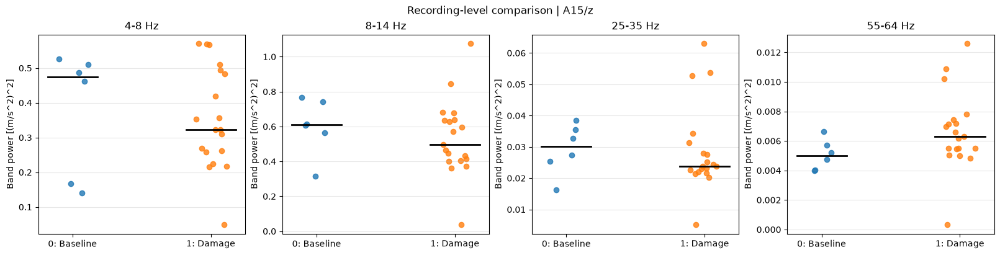

In [11]:
band_results = compare_band_energy(file_path, sensor=SENSOR, axis=AXIS)

## 6. פיצ׳רים סטטיסטיים וספקטרליים
19 מדדים לכל הקלטה. ממוצע, סטיית תקן, RMS, טווח, אסימטריה ו־kurtosis; הספק ספקטרלי, תדר דומיננטי, מרכז, פיזור ואנטרופיה; הספק מוחלט ויחסי בארבעה תחומים. כל נקודה היא הקלטה, והקו השחור הוא חציון. המדדים עשויים להיות מתואמים ואינם ראיות עצמאיות.


In [12]:
def extract_recording_features(file_path,sensor='A15',axis='z'):
    bands=[(4,8),(8,14),(25,35),(55,64)];results=[]
    for state,test,label,x,fs in recording_signals(file_path,sensor,axis):
        constant=bool(np.ptp(x)==0)
        row={'state':state,'recording':test,'label':label,'constant':constant,
             'mean':float(np.mean(x)),'std':float(np.std(x)),
             'rms':float(np.sqrt(np.mean(x**2))),'peak_to_peak':float(np.ptp(x)),
             'skewness':float(skew(x,bias=False)) if not constant else np.nan,
             'kurtosis':float(kurtosis(x,fisher=True,bias=False)) if not constant else np.nan}
        frequencies,psd=calculate_psd(x,fs);positive=frequencies>0
        f,p=frequencies[positive],psd[positive];total=float(trapezoid(p,f))
        row['total_spectral_power']=total
        if not constant and p.sum()>0:
            weights=p/p.sum();centroid=float(np.sum(f*weights));nonzero=weights>0
            row.update(dominant_frequency=float(f[np.argmax(p)]),spectral_centroid=centroid,
                       spectral_spread=float(np.sqrt(np.sum(weights*(f-centroid)**2))),
                       spectral_entropy=float(-np.sum(weights[nonzero]*np.log(weights[nonzero]))/np.log(len(weights))))
        else:
            for name in ['dominant_frequency','spectral_centroid','spectral_spread','spectral_entropy']:row[name]=np.nan
        for low,high in bands:
            if high>fs/2:raise ValueError('Band exceeds Nyquist')
            mask=(frequencies>=low)&(frequencies<=high)
            if mask.sum()<2:raise ValueError('Insufficient frequency bins')
            power=float(trapezoid(psd[mask],frequencies[mask]))
            row[f'power_{low}_{high}']=power
            row[f'fraction_{low}_{high}']=power/total if total>0 and not constant else np.nan
        results.append(row)
    return results

def plot_feature_comparison(results,feature_names=None):
    if not results:raise ValueError('No features supplied')
    if feature_names is None:
        feature_names=[k for k in results[0] if k not in {'state','recording','label','constant'}]
    if not feature_names:raise ValueError('No feature names supplied')
    columns=min(3,len(feature_names));rows=int(np.ceil(len(feature_names)/columns))
    fig,axes=plt.subplots(rows,columns,figsize=(5*columns,3.5*rows),squeeze=False,constrained_layout=True)
    rng=np.random.default_rng(42)
    for ax,feature in zip(axes.flat,feature_names):
        for label,color in [(0,'tab:blue'),(1,'tab:orange')]:
            values=np.array([r[feature] for r in results if r['label']==label],dtype=float)
            finite=np.isfinite(values)
            if not finite.all():print(feature,label,'undefined:',int((~finite).sum()))
            values=values[finite]
            if not len(values):continue
            ax.scatter(label+rng.uniform(-.12,.12,len(values)),values,color=color,alpha=.8)
            ax.plot([label-.18,label+.18],[np.median(values)]*2,color='black',lw=2)
        ax.set_title(feature);ax.set_xticks([0,1],['0: Baseline','1: Damage']);ax.grid(axis='y',alpha=.3)
    for ax in list(axes.flat)[len(feature_names):]:ax.set_visible(False)
    plt.show()
    return fig,axes

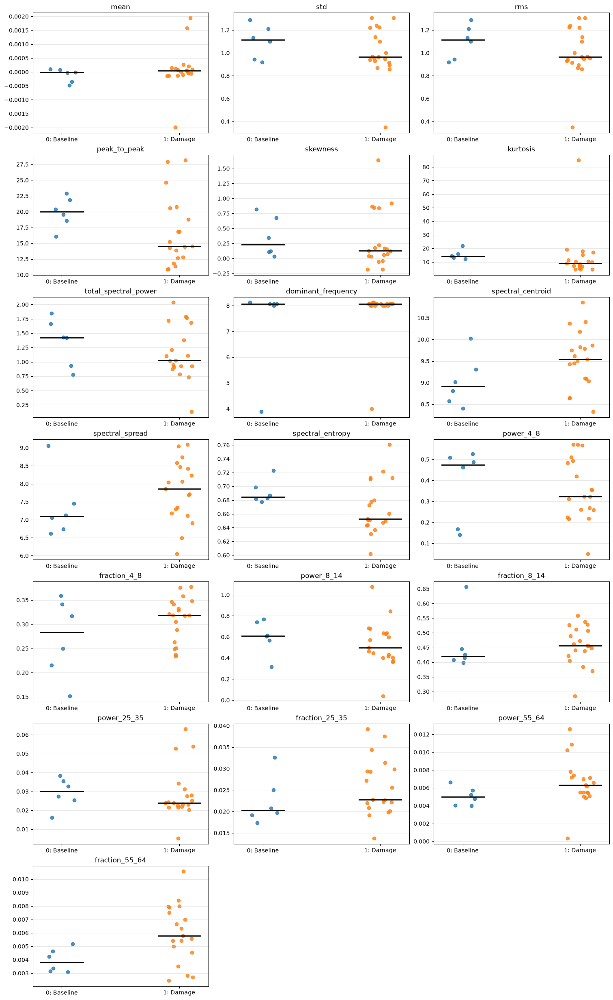

In [13]:
features = extract_recording_features(file_path, sensor=SENSOR, axis=AXIS)
fig, axes = plot_feature_comparison(features)


## 7. מקטעי זמן
מקטעים מלאים של 5 שניות בלבד, ללא חפיפה. המקטע הקצר בסוף אינו נכלל בהשוואה, כדי להימנע מהארטיפקט שראינו בגרף הקודם. המדידות המקוריות אינן נמחקות. הזמן הוא מתחילת ההקלטה; אין יישור אירועי העמסה ואין תיוג חדש ברמת מקטע.


In [14]:
def compare_time_frames(file_path,sensor='A15',axis='z',frame_seconds=5):
    if frame_seconds<=0:raise ValueError('Frame duration must be positive')
    results=[]
    for state,test,label,x,fs in recording_signals(file_path,sensor,axis):
        size=int(round(frame_seconds*fs))
        if size<2:raise ValueError('Frame too short')
        # Full frames only: the tiny final partial frames are not comparable.
        for start in range(0,len(x)-size+1,size):
            frame=x[start:start+size]
            results.append({'state':state,'recording':test,'label':label,
                            'time_center':(start+(size-1)/2)/fs,'duration':size/fs,
                            'mean':float(frame.mean()),'rms':float(np.sqrt(np.mean(frame**2))),
                            'std':float(frame.std())})
    fig,axes=plt.subplots(3,1,figsize=(13,9),sharex=True,constrained_layout=True)
    for ax,metric in zip(axes,['mean','rms','std']):
        for state,test in sorted({(r['state'],r['recording']) for r in results}):
            rows=[r for r in results if r['state']==state and r['recording']==test]
            color='tab:blue' if rows[0]['label']==0 else 'tab:orange'
            ax.plot([r['time_center'] for r in rows],[r[metric] for r in rows],color=color,alpha=.4,lw=1)
        ax.set_ylabel(f'{metric} [m/s^2]');ax.grid(alpha=.3)
    axes[0].plot([],[],color='tab:blue',label='0: Baseline');axes[0].plot([],[],color='tab:orange',label='1: Damage')
    axes[0].legend();axes[0].set_title(f'{sensor}/{axis} | {frame_seconds}s full frames')
    axes[-1].set_xlabel('Time from recording start [s]');plt.show()
    return results

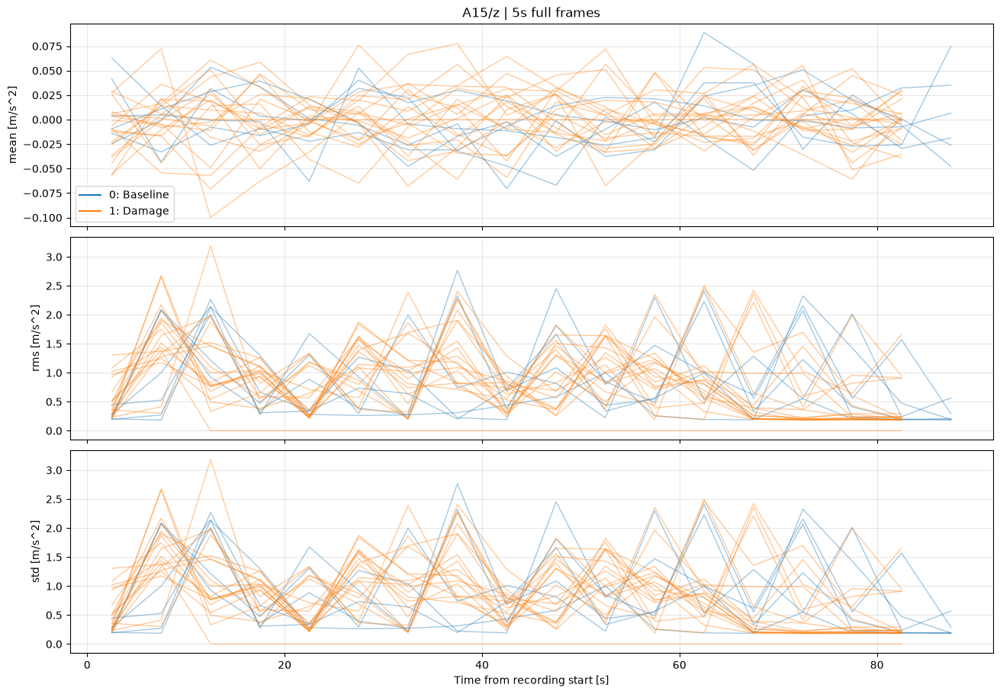

In [15]:
frame_results = compare_time_frames(file_path, sensor=SENSOR, axis=AXIS, frame_seconds=5)

## 8. MFCC באמצעות librosa — השוואה בין הקבוצות
8 מקדמים במקטעים של 512 דגימות (4 שניות ב־128 Hz), עם צעד 256 דגימות וללא ריפוד. לכל הקלטה מחשבים ממוצע וסטיית תקן לכל מקדם: 16 פיצ׳רים. אין ערבוב בין מקטעים כדוגמאות עצמאיות. מקדם אינו תדר ב־Hz; מקדם 0 רגיש לעוצמה. בטווח 0–64 Hz סולם Mel קרוב לליניארי, ולכן התרומה לחיזוי עדיין דורשת אימות.


In [16]:
def calculate_mfcc(data,fs=128):
    import librosa
    x=np.asarray(data,dtype=float).squeeze()
    if x.ndim!=1 or x.size<512 or not np.isfinite(x).all():
        raise ValueError('Expected one finite signal with at least 512 samples')
    if fs<=0:raise ValueError('Sample rate must be positive')
    coefficients=librosa.feature.mfcc(y=x,sr=fs,n_mfcc=8,n_mels=16,
                                     n_fft=512,hop_length=256,fmin=0,fmax=fs/2,center=False)
    return {'coefficients':coefficients,'mean':coefficients.mean(axis=1),'std':coefficients.std(axis=1)}

def compare_recording_mfcc(file_path,sensor='A15',axis='z'):
    results=[]
    for state,test,label,x,fs in recording_signals(file_path,sensor,axis):
        mfcc=calculate_mfcc(x,fs)
        row={'state':state,'recording':test,'label':label,'constant':bool(np.ptp(x)==0)}
        for i in range(len(mfcc['mean'])):
            row[f'mfcc_{i}_mean']=float(mfcc['mean'][i]);row[f'mfcc_{i}_std']=float(mfcc['std'][i])
        results.append(row)
    return results

One recording, coefficients x frames: (8, 44)


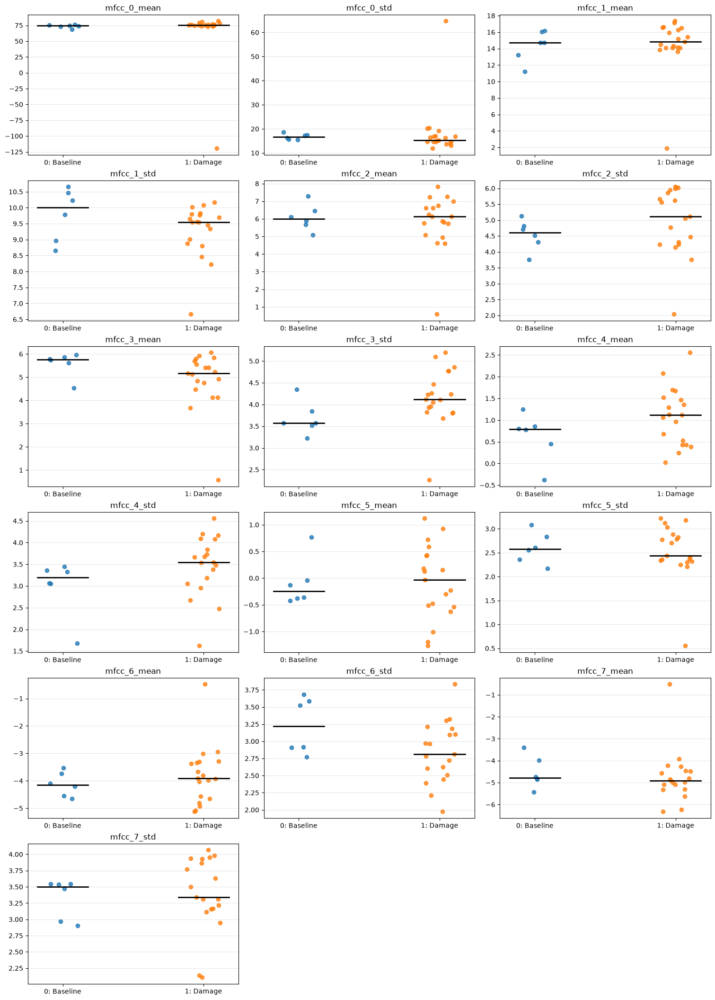

In [17]:
mfcc = calculate_mfcc(data, fs=fs)
print("One recording, coefficients x frames:", mfcc["coefficients"].shape)
mfcc_features = compare_recording_mfcc(file_path, sensor=SENSOR, axis=AXIS)
fig, axes = plot_feature_comparison(mfcc_features)


## 9. האם MFCC עוזרים לזיהוי נזק?
השוואה ראשונית עבור A15/Z: מסווג רוב, רגרסיה לוגיסטית עם 19 הפיצ׳רים הקודמים, עם 16 פיצ׳רי MFCC ועם השילוב שלהם. אותו מודל ואותם פיצולים לכל משפחות הפיצ׳רים, ללא בחירת פיצ׳רים או כוונון לפי התוצאות.

כל שורה היא הקלטה שלמה. מבצעים 3-fold stratified CV בחמישה זרעים: בכל קבוצת ולידציה 2 הקלטות בסיס ו־6 או 7 נזק. מזהה הקלטה אינו חוצה אימון וולידציה. מילוי ערכי פיצ׳רים לא מוגדרים ותקנון נלמדים בתוך האימון בלבד, ללא שינוי של האותות המקוריים.

המדדים הם balanced accuracy, recall של נזק, recall של בסיס, ROC-AUC ו־average precision. האחרון אינו אינטגרל טרפזי של עקומת PR. הפיזור בין 15 הסבבים הוא תיאור רגישות לפיצולים, לא רווח סמך של 15 ניסויים עצמאיים. אין כאן סט בדיקה סופי או הערכה על גשר אחר. הפיצ׳רים הספקטרליים כבר נבחרו חקרנית מהדאטה, ולכן ההשוואה ראשונית.


family,balanced_accuracy_mean,balanced_accuracy_std,damage_recall_mean,damage_recall_std,baseline_recall_mean,baseline_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
Majority baseline,0.5000,0.0000,1.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.7593,0.0131
Statistical + spectral (19),0.5603,0.1744,0.6873,0.1478,0.4333,0.3590,0.6857,0.2349,0.8968,0.0898
MFCC (16),0.7341,0.1461,0.7683,0.1234,0.7000,0.3559,0.7786,0.2284,0.9322,0.0880
Combined (35),0.6159,0.1729,0.7317,0.1707,0.5000,0.3651,0.7008,0.2224,0.9032,0.0843


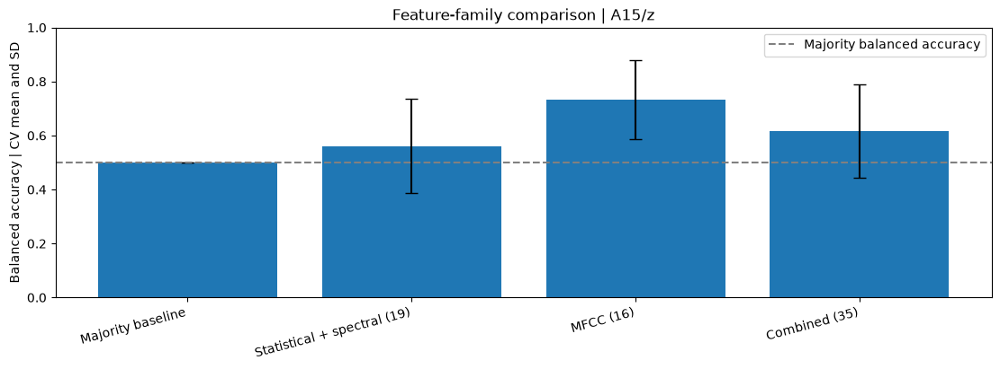

In [7]:
import html
from IPython.display import HTML, display
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (balanced_accuracy_score, recall_score,
                             roc_auc_score, average_precision_score)

def show_analysis_table(rows, columns=None):
    if not rows:
        print("No rows")
        return
    columns = columns or list(rows[0])
    def format_value(value):
        return f"{value:.4f}" if isinstance(value, (float, np.floating)) else str(value)
    header = ''.join(f'<th>{html.escape(str(c))}</th>' for c in columns)
    body = ''.join('<tr>'+''.join(
        f'<td>{html.escape(format_value(row.get(c, "")))}</td>'
        for c in columns)+'</tr>' for row in rows)
    display(HTML(f'<table><thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>'))

# Align feature families by recording identity rather than assuming row order.
old_by_key = {(r["state"], r["recording"]): r for r in features}
mfcc_by_key = {(r["state"], r["recording"]): r for r in mfcc_features}
assert len(old_by_key) == len(features) and len(mfcc_by_key) == len(mfcc_features)
assert set(old_by_key) == set(mfcc_by_key)
recording_keys = sorted(old_by_key)
excluded_columns = {"state", "recording", "label", "constant"}
old_names = [k for k in features[0] if k not in excluded_columns]
mfcc_names = [k for k in mfcc_features[0] if k not in excluded_columns]
all_feature_names = old_names + mfcc_names
y_eval = np.asarray([old_by_key[k]["label"] for k in recording_keys], dtype=int)
assert all(old_by_key[k]["label"] == mfcc_by_key[k]["label"] for k in recording_keys)
recording_groups = np.asarray([f"{s}/{t}" for s,t in recording_keys])
assert len(set(recording_groups)) == len(y_eval)
X_old = np.asarray([[old_by_key[k][n] for n in old_names] for k in recording_keys])
X_mfcc = np.asarray([[mfcc_by_key[k][n] for n in mfcc_names] for k in recording_keys])
X_all = np.column_stack([X_old, X_mfcc])

cv_partitions = []
for seed in range(42, 47):
    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    for fold, (train, validation) in enumerate(splitter.split(X_all, y_eval)):
        assert set(recording_groups[train]).isdisjoint(recording_groups[validation])
        assert set(y_eval[train]) == {0, 1} and set(y_eval[validation]) == {0, 1}
        cv_partitions.append((seed, fold+1, train, validation))

def evaluate_feature_family(name, X, dummy=False):
    scores = []
    for seed, fold, train, validation in cv_partitions:
        if dummy:
            model = DummyClassifier(strategy="most_frequent")
        else:
            model = make_pipeline(
                SimpleImputer(strategy="median", keep_empty_features=True),
                StandardScaler(),
                LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000)
            )
        model.fit(X[train], y_eval[train])
        prediction = model.predict(X[validation])
        probability = model.predict_proba(X[validation])[:, 1]
        scores.append({"family":name, "seed":seed, "fold":fold,
            "balanced_accuracy":float(balanced_accuracy_score(y_eval[validation],prediction)),
            "damage_recall":float(recall_score(y_eval[validation],prediction,pos_label=1)),
            "baseline_recall":float(recall_score(y_eval[validation],prediction,pos_label=0)),
            "roc_auc":float(roc_auc_score(y_eval[validation],probability)),
            "average_precision":float(average_precision_score(y_eval[validation],probability))})
    return scores

cv_scores = []
for name, matrix, dummy in [
    ("Majority baseline", np.zeros((len(y_eval),1)), True),
    ("Statistical + spectral (19)", X_old, False),
    ("MFCC (16)", X_mfcc, False),
    ("Combined (35)", X_all, False),
]:
    cv_scores.extend(evaluate_feature_family(name, matrix, dummy))

metric_names = ["balanced_accuracy", "damage_recall", "baseline_recall", "roc_auc", "average_precision"]
evaluation_summary = []
family_order = list(dict.fromkeys(r["family"] for r in cv_scores))
for name in family_order:
    selected = [r for r in cv_scores if r["family"]==name]
    row = {"family":name}
    for metric in metric_names:
        values = np.asarray([r[metric] for r in selected])
        row[metric+"_mean"] = float(values.mean())
        row[metric+"_std"] = float(values.std())
    evaluation_summary.append(row)
show_analysis_table(evaluation_summary)

fig, ax = plt.subplots(figsize=(11,4), constrained_layout=True)
ax.bar(np.arange(len(evaluation_summary)),
       [r["balanced_accuracy_mean"] for r in evaluation_summary],
       yerr=[r["balanced_accuracy_std"] for r in evaluation_summary], capsize=5)
ax.set_xticks(np.arange(len(evaluation_summary)), family_order, rotation=15, ha="right")
ax.axhline(0.5, color="gray", linestyle="--", label="Majority balanced accuracy")
ax.set_ylim(0,1); ax.set_ylabel("Balanced accuracy | CV mean and SD")
ax.set_title(f"Feature-family comparison | {SENSOR}/{AXIS}"); ax.legend(); plt.show()


## 10. קורלציה בין הפיצ׳רים לבין התווית
לתווית בינארית ולפיצ׳ר רציף נשתמש בקורלציה point-biserial, השקולה ל־Pearson במקרה זה. נוסיף Spearman כדי לבחון קשר המבוסס על דירוג ופחות תלוי בגודל ערכים קיצוניים. סימן חיובי פירושו ערכים גבוהים יותר בקבוצת הנזק; סימן שלילי פירושו ערכים נמוכים יותר.

הטבלה מחושבת על 25 ההקלטות לצורך חקירה בלבד, ולא שימשה לבחירת פיצ׳רים בהערכת המודל. p-values מתוקנים במשותף ל־35 בדיקות Pearson באמצעות Benjamini–Hochberg. גם התיקון אינו פותר את התלות האפשרית בין ניסויים באותו גשר או בחירה חקרנית קודמת. קורלציה גבוהה אינה הוכחת סיבתיות או תרומה עצמאית למודל, וקורלציה נמוכה אינה שוללת קשר לא ליניארי.


feature,family,n,pearson_r,abs_r,spearman_r,p_value,q_value_BH
fraction_55_64,Statistical/spectral,25,0.4161,0.4161,0.4286,0.0386,0.6016
mfcc_6_std,MFCC,25,-0.3648,0.3648,-0.3247,0.0730,0.6016
mfcc_3_std,MFCC,25,0.3469,0.3469,0.4546,0.0893,0.6016
spectral_centroid,Statistical/spectral,25,0.3450,0.3450,0.3637,0.0912,0.6016
mfcc_4_mean,MFCC,25,0.3029,0.3029,0.2598,0.1411,0.6016
fraction_4_8,Statistical/spectral,25,0.2997,0.2997,0.2078,0.1455,0.6016
mfcc_4_std,MFCC,25,0.2940,0.2940,0.3507,0.1538,0.6016
power_55_64,Statistical/spectral,25,0.2897,0.2897,0.4026,0.1602,0.6016
peak_to_peak,Statistical/spectral,25,-0.2760,0.2760,-0.3507,0.1817,0.6016
spectral_entropy,Statistical/spectral,25,-0.2724,0.2724,-0.3767,0.1878,0.6016


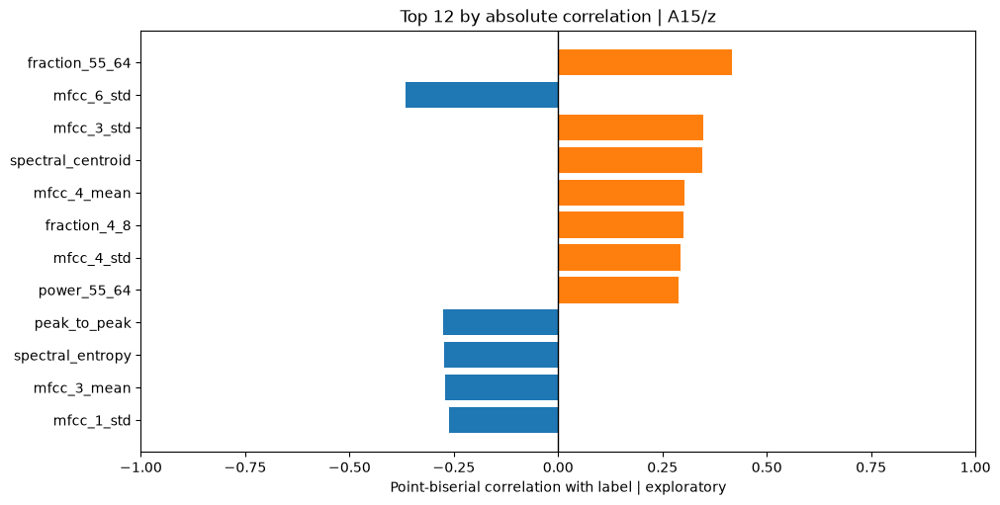

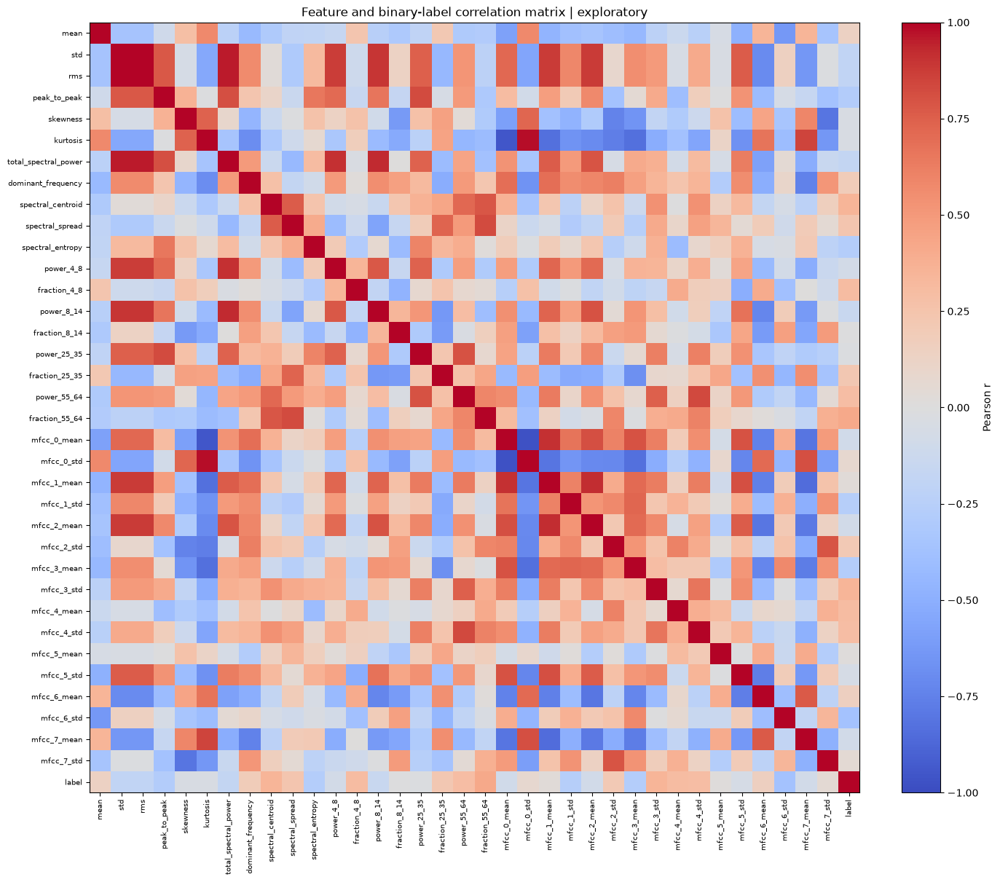

Saved analysis report: C:\project_ML\BridgePulse\outputs\mfcc_evaluation.json


In [8]:
from scipy.stats import pointbiserialr, spearmanr

correlation_rows = []
for j, name in enumerate(all_feature_names):
    valid = np.isfinite(X_all[:,j])
    x = X_all[valid,j]; labels = y_eval[valid]
    if len(x)<3 or len(np.unique(labels))<2 or np.ptp(x)==0:
        r, p, rho = np.nan, np.nan, np.nan
    else:
        result = pointbiserialr(labels, x)
        r, p = float(result.statistic), float(result.pvalue)
        rho = float(spearmanr(labels, x).statistic)
    correlation_rows.append({"feature":name, "family":"MFCC" if name.startswith("mfcc_") else "Statistical/spectral",
                             "n":int(valid.sum()), "pearson_r":r, "abs_r":abs(r),
                             "spearman_r":rho, "p_value":p, "q_value_BH":np.nan})

finite_indices = [i for i,r in enumerate(correlation_rows) if np.isfinite(r["p_value"])]
order = sorted(finite_indices, key=lambda i: correlation_rows[i]["p_value"])
if order:
    p_values = np.asarray([correlation_rows[i]["p_value"] for i in order])
    adjusted = p_values * len(order) / np.arange(1,len(order)+1)
    adjusted = np.minimum(1, np.minimum.accumulate(adjusted[::-1])[::-1])
    for i,q in zip(order,adjusted): correlation_rows[i]["q_value_BH"] = float(q)
correlation_rows.sort(key=lambda r:r["abs_r"] if np.isfinite(r["abs_r"]) else -1, reverse=True)
show_analysis_table(correlation_rows)

top_rows = [r for r in correlation_rows if np.isfinite(r["pearson_r"])][:12]
fig, ax = plt.subplots(figsize=(10,5), constrained_layout=True)
ax.barh([r["feature"] for r in top_rows], [r["pearson_r"] for r in top_rows],
        color=["tab:orange" if r["pearson_r"]>0 else "tab:blue" for r in top_rows])
ax.invert_yaxis(); ax.axvline(0,color="black",lw=1); ax.set_xlim(-1,1)
ax.set_xlabel("Point-biserial correlation with label | exploratory")
ax.set_title(f"Top 12 by absolute correlation | {SENSOR}/{AXIS}"); plt.show()

# Pairwise correlations show potentially redundant features as well as label relationships.
matrix_data = np.column_stack([X_all, y_eval])
matrix_names = all_feature_names + ["label"]
correlation_matrix = np.full((len(matrix_names),len(matrix_names)),np.nan)
for i in range(len(matrix_names)):
    for j in range(i,len(matrix_names)):
        valid = np.isfinite(matrix_data[:,i]) & np.isfinite(matrix_data[:,j])
        a,b = matrix_data[valid,i],matrix_data[valid,j]
        if len(a)>=3 and np.ptp(a)>0 and np.ptp(b)>0:
            value = float(np.corrcoef(a,b)[0,1])
            correlation_matrix[i,j] = correlation_matrix[j,i] = value
fig, ax = plt.subplots(figsize=(14,12),constrained_layout=True)
im = ax.imshow(correlation_matrix,vmin=-1,vmax=1,cmap="coolwarm")
ax.set_xticks(np.arange(len(matrix_names)),matrix_names,rotation=90,fontsize=7)
ax.set_yticks(np.arange(len(matrix_names)),matrix_names,fontsize=7)
ax.set_title("Feature and binary-label correlation matrix | exploratory")
fig.colorbar(im,ax=ax,label="Pearson r"); plt.show()

# Small report only; original measurements are not written or altered.
import json
report_path = ROOT / "outputs" / "mfcc_evaluation.json"
report_path.parent.mkdir(exist_ok=True)
with report_path.open("w",encoding="utf-8") as stream:
    json.dump({"sensor":SENSOR,"axis":AXIS,"recordings":len(y_eval),
               "evaluation":evaluation_summary,"fold_scores":cv_scores,
               "correlations":correlation_rows},stream,ensure_ascii=False,indent=2)
print("Saved analysis report:",report_path)


## 11. השוואת כל חיישני התאוצה — MFCC בציר Z
אותו מבחן לכל חיישן: 16 פיצ׳רי MFCC, רגרסיה לוגיסטית עם אותן הגדרות ו־15 פיצולי הוולידציה משלב 9. בכל פיצול ההקלטות השלמות נפרדות; תקנון נלמד רק באימון. התוצאות נמדדות על הקלטות ולידציה, לא על נתוני האימון.

הדירוג הוא יכולת זיהוי של כל חיישן לבדו, ולא תרומתו העצמאית במודל משותף או חשיבות פיזיקלית. פיזור בין סבבים אינו רווח סמך. בחירת המנצח מתוך 30 חיישנים יוצרת אופטימיות, ולכן דרושה הערכה חיצונית/מקוננת לפני הצגת הציון כביצוע סופי. אין הוכחה להכללה לגשר אחר.

A14 נשאר בנתונים ובטבלה אך מסומן כבעיית איכות: ארבע הקלטות damage_6 שלו קבועות. הוא אינו נכלל בדירוג החיישנים ללא ערוצים קבועים, כדי לא לפרש כשל מדידה כסימן לנזק. שאר המדידות המקוריות אינן משתנות.


Completed 5/30 sensors


Completed 10/30 sensors


Completed 15/30 sensors


Completed 20/30 sensors


Completed 25/30 sensors


Completed 30/30 sensors


rank,sensor,axis,balanced_accuracy_mean,balanced_accuracy_std,baseline_recall_mean,damage_recall_mean,roc_auc_mean,constant_recordings,quality
1,A26,z,0.8825,0.0979,0.9000,0.8651,0.9841,0,No constant recordings
2,A29,z,0.8778,0.1138,0.9000,0.8556,0.9746,0,No constant recordings
3,A28,z,0.8452,0.2053,0.8333,0.8571,0.9317,0,No constant recordings
4,A20,z,0.8349,0.0968,0.8667,0.8032,0.9119,0,No constant recordings
5,A09,z,0.8159,0.1226,0.8000,0.8317,0.9159,0,No constant recordings
6,A04,z,0.8071,0.1654,0.7667,0.8476,0.8500,0,No constant recordings
7,A21,z,0.7960,0.1992,0.7667,0.8254,0.9437,0,No constant recordings
8,A25,z,0.7833,0.1974,0.7333,0.8333,0.8778,0,No constant recordings
9,A30,z,0.7794,0.1475,0.7333,0.8254,0.9524,0,No constant recordings
10,A02,z,0.7778,0.1391,0.7667,0.7889,0.8056,0,No constant recordings


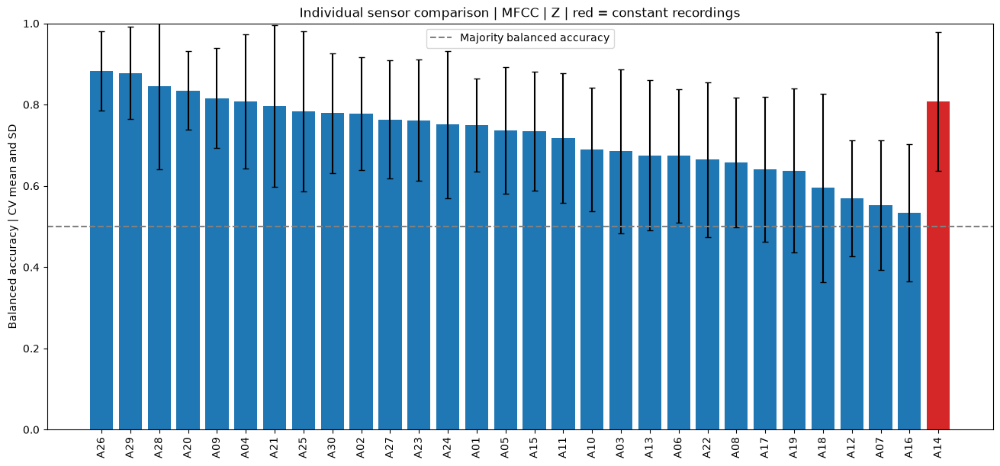

Saved sensor comparison: C:\project_ML\BridgePulse\outputs\sensor_mfcc_comparison.json


In [8]:
import json
COMPARISON_AXIS = "z"

with h5py.File(file_path, "r") as sensor_file:
    common_sensors = None
    for state in STATE_LABELS:
        for group in sensor_file[state]["acceleration"].values():
            available = {sensor for sensor in group if COMPARISON_AXIS in group[sensor]}
            common_sensors = available if common_sensors is None else common_sensors & available
sensor_names = sorted(common_sensors)
assert len(sensor_names) == 30

sensor_summary = []
sensor_fold_scores = []
sensor_mfcc_features = {}
for sensor_index, sensor_name in enumerate(sensor_names, start=1):
    sensor_features = compare_recording_mfcc(file_path, sensor=sensor_name, axis=COMPARISON_AXIS)
    by_key = {(r["state"],r["recording"]):r for r in sensor_features}
    assert len(by_key)==len(sensor_features) and set(by_key)==set(recording_keys)
    assert all(by_key[k]["label"]==y_eval[i] for i,k in enumerate(recording_keys))
    sensor_matrix = np.asarray([[by_key[k][name] for name in mfcc_names] for k in recording_keys])
    assert sensor_matrix.shape == (25,16) and np.isfinite(sensor_matrix).all()
    sensor_mfcc_features[sensor_name] = sensor_features
    scores = evaluate_feature_family(sensor_name, sensor_matrix)
    sensor_fold_scores.extend(scores)
    flat_records = [f"{s}/{t}" for (s,t),r in by_key.items() if r["constant"]]
    summary = {"sensor":sensor_name, "axis":COMPARISON_AXIS,
               "recordings":len(sensor_features), "features":len(mfcc_names),
               "constant_recordings":len(flat_records),
               "quality":"Constant recordings: inspect measurement failure" if flat_records else "No constant recordings",
               "flat_record_ids":flat_records}
    for metric in metric_names:
        values = np.asarray([row[metric] for row in scores])
        summary[metric+"_mean"] = float(values.mean())
        summary[metric+"_std"] = float(values.std())
    sensor_summary.append(summary)
    if sensor_index % 5 == 0:
        print(f"Completed {sensor_index}/{len(sensor_names)} sensors")

# Sort valid-quality sensors first, while retaining flagged sensors in the table.
sensor_summary.sort(key=lambda r:(r["constant_recordings"]>0, -r["balanced_accuracy_mean"]))
usable_rank = 0
for row in sensor_summary:
    if row["constant_recordings"]==0:
        usable_rank += 1
        row["rank"] = usable_rank
    else:
        row["rank"] = "QC flag"
show_analysis_table(sensor_summary, columns=[
    "rank","sensor","axis","balanced_accuracy_mean","balanced_accuracy_std",
    "baseline_recall_mean","damage_recall_mean","roc_auc_mean",
    "constant_recordings","quality"
])

fig,ax = plt.subplots(figsize=(13,6),constrained_layout=True)
positions = np.arange(len(sensor_summary))
colors = ["tab:red" if row["constant_recordings"] else "tab:blue" for row in sensor_summary]
ax.bar(positions,[row["balanced_accuracy_mean"] for row in sensor_summary],
       yerr=[row["balanced_accuracy_std"] for row in sensor_summary],color=colors,capsize=3)
ax.set_xticks(positions,[row["sensor"] for row in sensor_summary],rotation=90)
ax.axhline(0.5,color="gray",linestyle="--",label="Majority balanced accuracy")
ax.set_ylim(0,1);ax.set_ylabel("Balanced accuracy | CV mean and SD")
ax.set_title("Individual sensor comparison | MFCC | Z | red = constant recordings")
ax.legend();plt.show()

sensor_report_path = ROOT / "outputs" / "sensor_mfcc_comparison.json"
with sensor_report_path.open("w",encoding="utf-8") as stream:
    json.dump({"axis":COMPARISON_AXIS,"recordings":len(y_eval),"features_per_sensor":len(mfcc_names),
               "method":"Same 3-fold CV, 5 seeds, balanced logistic regression; one row per recording",
               "ranking_is_exploratory":True,"summary":sensor_summary,"fold_scores":sensor_fold_scores},
              stream,ensure_ascii=False,indent=2)
print("Saved sensor comparison:",sensor_report_path)


## 12. אימון על כל הפיצ׳רים המוגדרים — Logistic Regression עם L2
35 פיצ׳רים לכל ערוץ תאוצה: 19 סטטיסטיים/ספקטרליים ו־16 MFCC. משתמשים בשני הצירים של 29 חיישנים, ללא A14 בגלל ארבע הקלטות שטוחות במצב damage_6. בסך הכול 2030 פיצ׳רים ו־25 הקלטות. זהו כל סט הפיצ׳רים שהגדרנו עד כה, ולא כל פיצ׳ר אפשרי תאורטית. נתוני מעוותים אינם מצורפים, משום שאין התאמה מתועדת בין הקלטות התאוצה להעמסות של נתוני המעוותים.

חלוקה שחזורית ומאוזנת לפי תווית: 17 אימון, 4 ולידציה, 4 בדיקה (68/16/16, קירוב ל־70/15/15). כל הקלטה שלמה וכל החיישנים שלה נשארים יחד. זוהי בדיקה פנימית בלבד: ההקלטות כבר נצפו בניתוחים קודמים, ולכן היא אינה סט בדיקה חדש ועיוור למחקר כולו.

Pipeline: מילוי פיצ׳רים לא מוגדרים בחציון האימון, הסרת פיצ׳רים קבועים לפי האימון, ו־StandardScaler (ממוצע 0 וסטיית תקן 1). זו פעולה על טבלת הפיצ׳רים בלבד; האותות המקוריים אינם משתנים. כל השלבים נלמדים מחדש בתוך כל פיצול אימון.

עוצמת L2 נבחרת ב־3-fold CV בתוך 17 הקלטות האימון, לפי balanced accuracy. מדווחים ולידציה, ואז מאמנים מחדש עם C שנבחר על אימון+ולידציה (21 הקלטות) ובודקים פעם אחת על ארבע הקלטות הבדיקה. סט הבדיקה אינו משתתף בתקנון או בבחירת C. אין שימוש בדירוג החיישנים או בקורלציות לבחירת פיצ׳רים. 2030 פיצ׳רים מול 25 הקלטות הם ניסוי עתיר פיצ׳רים עם אי־ודאות גדולה; רגולריזציה אינה מבטיחה הכללה.


In [8]:
import json
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, recall_score,
                             precision_score, roc_auc_score, average_precision_score,
                             confusion_matrix)

excluded_sensors_all = {"A14"}
all_axes = ("y", "z")
with h5py.File(file_path, "r") as raw_file:
    sensor_sets = [set(group.keys()) for state in STATE_LABELS
                   for group in raw_file[state]["acceleration"].values()]
all_sensors = sorted(set.intersection(*sensor_sets)-excluded_sensors_all)
assert len(all_sensors)==29

all_features_by_record = {}
all_feature_columns = []
feature_identity_exclusions = {"state","recording","label","constant"}
for sensor_number,sensor_name in enumerate(all_sensors,start=1):
    for axis_name in all_axes:
        stats_rows = extract_recording_features(file_path,sensor=sensor_name,axis=axis_name)
        mfcc_rows = compare_recording_mfcc(file_path,sensor=sensor_name,axis=axis_name)
        stats_by_key = {(r["state"],r["recording"]):r for r in stats_rows}
        mfcc_by_key_all = {(r["state"],r["recording"]):r for r in mfcc_rows}
        assert set(stats_by_key)==set(mfcc_by_key_all) and len(stats_by_key)==25
        if all_features_by_record:
            assert set(stats_by_key)==set(all_features_by_record)
        for family_rows in (stats_by_key,mfcc_by_key_all):
            example = next(iter(family_rows.values()))
            local_names = [n for n in example if n not in feature_identity_exclusions]
            column_names = [f"{sensor_name}_{axis_name}_{n}" for n in local_names]
            all_feature_columns.extend(column_names)
            for key,row in family_rows.items():
                target = all_features_by_record.setdefault(key,{"label":row["label"]})
                assert target["label"]==row["label"]
                target.update({column:row[name] for column,name in zip(column_names,local_names)})
    if sensor_number % 5 == 0 or sensor_number==len(all_sensors):
        print(f"Extracted both axes for {sensor_number}/{len(all_sensors)} sensors")

all_recording_keys = sorted(all_features_by_record)
all_record_ids = np.asarray([f"{s}/{t}" for s,t in all_recording_keys])
all_y = np.asarray([all_features_by_record[k]["label"] for k in all_recording_keys],dtype=int)
all_X = np.asarray([[all_features_by_record[k][n] for n in all_feature_columns]
                    for k in all_recording_keys],dtype=float)
assert all_X.shape==(25,2030)
assert len(set(all_feature_columns))==2030 and len(set(all_record_ids))==25
assert not np.isinf(all_X).any()

indices = np.arange(len(all_y))
train_validation_indices, all_test_indices = train_test_split(
    indices,test_size=4,stratify=all_y,random_state=42)
all_train_indices, all_validation_indices = train_test_split(
    train_validation_indices,test_size=4,
    stratify=all_y[train_validation_indices],random_state=43)
all_train_indices=np.sort(all_train_indices)
all_validation_indices=np.sort(all_validation_indices)
all_test_indices=np.sort(all_test_indices)
assert set(all_train_indices).isdisjoint(all_validation_indices)
assert set(all_train_indices).isdisjoint(all_test_indices)
assert set(all_validation_indices).isdisjoint(all_test_indices)
assert set(all_train_indices)|set(all_validation_indices)|set(all_test_indices)==set(indices)
print("Feature matrix:",all_X.shape,"Non-finite features:",int((~np.isfinite(all_X)).sum()))
split_rows=[]
for split_name,split_idx in [("train",all_train_indices),("validation",all_validation_indices),("test",all_test_indices)]:
    counts=np.bincount(all_y[split_idx],minlength=2)
    split_rows.append({"split":split_name,"recordings":len(split_idx),"baseline":int(counts[0]),"damage":int(counts[1])})
show_analysis_table(split_rows)


Extracted both axes for 5/29 sensors


Extracted both axes for 10/29 sensors


Extracted both axes for 15/29 sensors


Extracted both axes for 20/29 sensors


Extracted both axes for 25/29 sensors


Extracted both axes for 29/29 sensors
Feature matrix: (25, 2030) Non-finite features: 0


split,recordings,baseline,damage
train,17,4,13
validation,4,1,3
test,4,1,3


C,cv_balanced_accuracy_mean,cv_balanced_accuracy_std
0.0001,0.5250,0.2761
0.0010,0.5250,0.2761
0.0100,0.5250,0.2761
0.1000,0.5583,0.2383
1.0000,0.6000,0.2944
10.0000,0.6000,0.2944


Selected C (training CV only): 1.0


split,recordings,accuracy,balanced_accuracy,damage_recall,baseline_recall,damage_precision,roc_auc,average_precision
validation (fit on 17),4,0.5000,0.3333,0.6667,0.0000,0.6667,0.6667,0.9167
test (fit on 21),4,0.5000,0.3333,0.6667,0.0000,0.6667,0.6667,0.9167


recording,true_label,prediction,damage_probability
baseline_2/test_1,0,1,0.6971
damage_3/test_1,1,1,0.9947
damage_4/test_2,1,1,0.9997
damage_6/test_3,1,0,0.0000


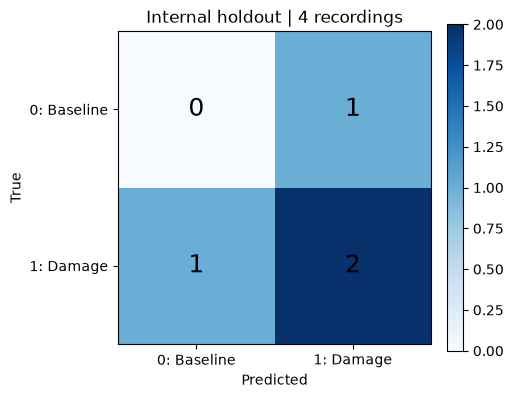

Saved model: C:\project_ML\BridgePulse\models\logistic_all_features.joblib
Saved feature table: C:\project_ML\BridgePulse\data\processed\all_acceleration_features.npz
Saved report: C:\project_ML\BridgePulse\outputs\logistic_all_features_report.json


In [9]:
all_feature_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
    ("nonconstant",VarianceThreshold(threshold=0)),
    ("scaler",StandardScaler()),
    ("classifier",LogisticRegression(solver="lbfgs",class_weight="balanced",max_iter=5000)),
])
inner_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=44)
parameter_search=GridSearchCV(
    all_feature_pipeline,
    param_grid={"classifier__C":[0.0001,0.001,0.01,0.1,1.0,10.0]},
    scoring="balanced_accuracy",cv=inner_cv,refit=True,n_jobs=1,error_score="raise")
parameter_search.fit(all_X[all_train_indices],all_y[all_train_indices])
best_C=float(parameter_search.best_params_["classifier__C"])
cv_parameter_rows=[]
for i,parameters in enumerate(parameter_search.cv_results_["params"]):
    cv_parameter_rows.append({"C":float(parameters["classifier__C"]),
        "cv_balanced_accuracy_mean":float(parameter_search.cv_results_["mean_test_score"][i]),
        "cv_balanced_accuracy_std":float(parameter_search.cv_results_["std_test_score"][i])})
show_analysis_table(cv_parameter_rows)
print("Selected C (training CV only):",best_C)

def evaluate_all_feature_model(model, X, y, split_name):
    prediction=model.predict(X);probability=model.predict_proba(X)[:,1]
    metrics={"split":split_name,"recordings":len(y),
        "accuracy":float(accuracy_score(y,prediction)),
        "balanced_accuracy":float(balanced_accuracy_score(y,prediction)),
        "damage_recall":float(recall_score(y,prediction,pos_label=1,zero_division=0)),
        "baseline_recall":float(recall_score(y,prediction,pos_label=0,zero_division=0)),
        "damage_precision":float(precision_score(y,prediction,pos_label=1,zero_division=0)),
        "roc_auc":float(roc_auc_score(y,probability)),
        "average_precision":float(average_precision_score(y,probability))}
    return metrics,prediction,probability

validation_metrics,validation_prediction,validation_probability=evaluate_all_feature_model(
    parameter_search.best_estimator_,all_X[all_validation_indices],all_y[all_validation_indices],"validation (fit on 17)")
final_all_feature_model=Pipeline([
    ("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
    ("nonconstant",VarianceThreshold(threshold=0)),
    ("scaler",StandardScaler()),
    ("classifier",LogisticRegression(C=best_C,solver="lbfgs",class_weight="balanced",max_iter=5000)),
])
final_fit_indices=np.sort(np.concatenate([all_train_indices,all_validation_indices]))
assert set(final_fit_indices).isdisjoint(all_test_indices)
final_all_feature_model.fit(all_X[final_fit_indices],all_y[final_fit_indices])
test_metrics,test_prediction,test_probability=evaluate_all_feature_model(
    final_all_feature_model,all_X[all_test_indices],all_y[all_test_indices],"test (fit on 21)")
show_analysis_table([validation_metrics,test_metrics])
test_predictions=[{"recording":str(all_record_ids[i]),"true_label":int(all_y[i]),
                   "prediction":int(pred),"damage_probability":float(prob)}
                  for i,pred,prob in zip(all_test_indices,test_prediction,test_probability)]
show_analysis_table(test_predictions)
cm=confusion_matrix(all_y[all_test_indices],test_prediction,labels=[0,1])
fig,ax=plt.subplots(figsize=(5,4),constrained_layout=True)
im=ax.imshow(cm,cmap="Blues",vmin=0)
for i in range(2):
    for j in range(2):ax.text(j,i,str(cm[i,j]),ha="center",va="center",fontsize=18)
ax.set_xticks([0,1],["0: Baseline","1: Damage"])
ax.set_yticks([0,1],["0: Baseline","1: Damage"])
ax.set_xlabel("Predicted");ax.set_ylabel("True");ax.set_title("Internal holdout | 4 recordings")
fig.colorbar(im,ax=ax);plt.show()

models_dir=ROOT/"models";models_dir.mkdir(exist_ok=True)
model_path=models_dir/"logistic_all_features.joblib"
bundle={"pipeline":final_all_feature_model,"feature_names":all_feature_columns,
        "sensors":all_sensors,"axes":list(all_axes),"excluded_sensors":sorted(excluded_sensors_all),
        "label_mapping":STATE_LABELS,"feature_settings":{"welch_segment_seconds":16,"mfcc_n_fft":512,
        "mfcc_hop_length":256,"mfcc_n_mels":16,"mfcc_n_mfcc":8},
        "fit_recordings":all_record_ids[final_fit_indices].tolist(),"test_recordings":all_record_ids[all_test_indices].tolist()}
joblib.dump(bundle,model_path)
processed_dir=ROOT/"data/processed";processed_dir.mkdir(exist_ok=True)
np.savez_compressed(processed_dir/"all_acceleration_features.npz",X=all_X,y=all_y,
                    feature_names=np.asarray(all_feature_columns),record_ids=all_record_ids,
                    train_indices=all_train_indices,validation_indices=all_validation_indices,test_indices=all_test_indices)
report={"method":"L2 logistic regression, training-only C selection, feature standardization inside pipeline",
        "source":"data/raw/Rt345Bridge.h5","recordings":len(all_y),"input_features":len(all_feature_columns),
        "retained_features":int(final_all_feature_model.named_steps["nonconstant"].get_support().sum()),
        "excluded_sensors":sorted(excluded_sensors_all),"split_seed_test":42,"split_seed_validation":43,
        "split_counts":split_rows,"best_C":best_C,"training_cv":cv_parameter_rows,
        "validation_metrics":validation_metrics,"test_metrics":test_metrics,
        "test_predictions":test_predictions,"confusion_matrix":cm.tolist(),
        "prior_exploration_warning":"All recordings were previously inspected; not a fresh blind study-level test set"}
report_path=ROOT/"outputs/logistic_all_features_report.json"
with report_path.open("w",encoding="utf-8") as stream:json.dump(report,stream,ensure_ascii=False,indent=2)
print("Saved model:",model_path)
print("Saved feature table:",processed_dir/"all_acceleration_features.npz")
print("Saved report:",report_path)


## 13. השוואה למודלים מורכבים יותר
אותם 2030 פיצ׳רים ואותו פיצול 17/4/4 משלב 12. מכוונים SVM עם RBF, Random Forest ו־Extra Trees באמצעות 3-fold CV בתוך האימון בלבד. מילוי ותקנון נלמדים בתוך ה־Pipeline. Logistic Regression היא נקודת הייחוס מהניסוי הקודם.

מדווחים ולידציה לאחר אימון על 17 הקלטות, ואז מאמנים כל הגדרה שנבחרה על אימון+ולידציה ובודקים על אותן 4 הקלטות. סט הבדיקה כבר נצפה, ולכן זו השוואה חקרנית ולא הערכה עיוורת חדשה. אין בחירת פרמטרים לפי הבדיקה. ארבע הקלטות ובהן בסיס אחד בלבד אינן מספיקות לאמידת ביצועים יציבה. יותר מורכבות אינה מבטיחה שיפור.


Completed: SVM RBF


Completed: Random Forest


Completed: Extra Trees


model,training_cv,validation_balanced_accuracy,test_balanced_accuracy,test_accuracy,test_baseline_recall,test_damage_recall,test_roc_auc
Logistic L2,0.6000,0.3333,0.3333,0.5000,0.0000,0.6667,0.6667
SVM RBF,0.5667,0.5000,0.5000,0.2500,1.0000,0.0000,1.0000
Random Forest,0.6333,0.5000,0.3333,0.5000,0.0000,0.6667,0.6667
Extra Trees,0.6333,0.5000,0.3333,0.5000,0.0000,0.6667,0.6667


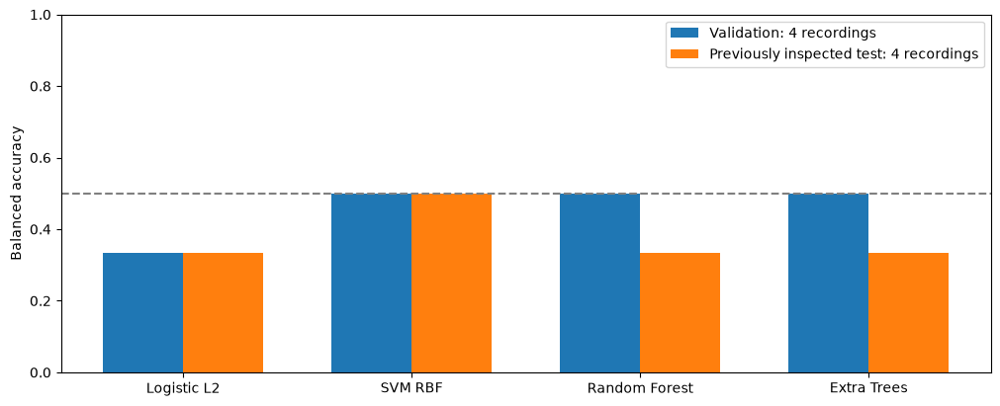

In [3]:
import json
import joblib
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, roc_auc_score, average_precision_score

with np.load(ROOT / "data/processed/all_acceleration_features.npz") as saved:
    comparison_X = saved["X"]
    comparison_y = saved["y"]
    comparison_names = saved["feature_names"].tolist()
    comparison_ids = saved["record_ids"]
    comparison_train = saved["train_indices"]
    comparison_validation = saved["validation_indices"]
    comparison_test = saved["test_indices"]
assert set(comparison_ids[comparison_train]).isdisjoint(comparison_ids[comparison_test])
assert set(comparison_ids[comparison_validation]).isdisjoint(comparison_ids[comparison_test])
comparison_fit = np.sort(np.concatenate([comparison_train,comparison_validation]))
comparison_cv = StratifiedKFold(n_splits=3,shuffle=True,random_state=44)

def complex_metrics(model, X, y):
    prediction = model.predict(X)
    score = model.decision_function(X) if hasattr(model,"decision_function") else model.predict_proba(X)[:,1]
    return {"accuracy":float(accuracy_score(y,prediction)),
            "balanced_accuracy":float(balanced_accuracy_score(y,prediction)),
            "baseline_recall":float(recall_score(y,prediction,pos_label=0,zero_division=0)),
            "damage_recall":float(recall_score(y,prediction,pos_label=1,zero_division=0)),
            "roc_auc":float(roc_auc_score(y,score)),
            "average_precision":float(average_precision_score(y,score))},prediction

specifications = [
    ("SVM RBF",SVC(kernel="rbf",class_weight="balanced"),
     {"classifier__C":[0.01,0.1,1,10],"classifier__gamma":["scale",0.0001]}),
    ("Random Forest",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=1),
     {"classifier__max_depth":[2,4,None],"classifier__min_samples_leaf":[1,3]}),
    ("Extra Trees",ExtraTreesClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=1),
     {"classifier__max_depth":[2,4,None],"classifier__min_samples_leaf":[1,3]}),
]
previous_report = json.loads((ROOT/"outputs/logistic_all_features_report.json").read_text(encoding="utf-8"))
complex_summary = [{"model":"Logistic L2",
                    "training_cv":max(r["cv_balanced_accuracy_mean"] for r in previous_report["training_cv"]),
                    "validation_balanced_accuracy":previous_report["validation_metrics"]["balanced_accuracy"],
                    "test_balanced_accuracy":previous_report["test_metrics"]["balanced_accuracy"],
                    "test_accuracy":previous_report["test_metrics"]["accuracy"],
                    "test_baseline_recall":previous_report["test_metrics"]["baseline_recall"],
                    "test_damage_recall":previous_report["test_metrics"]["damage_recall"],
                    "test_roc_auc":previous_report["test_metrics"]["roc_auc"]}]
complex_details=[]
for name,estimator,parameters in specifications:
    pipeline=Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
                       ("nonconstant",VarianceThreshold()),("scaler",StandardScaler()),
                       ("classifier",estimator)])
    search=GridSearchCV(pipeline,parameters,scoring="balanced_accuracy",cv=comparison_cv,n_jobs=1,error_score="raise")
    search.fit(comparison_X[comparison_train],comparison_y[comparison_train])
    validation_metrics,_=complex_metrics(search.best_estimator_,comparison_X[comparison_validation],comparison_y[comparison_validation])
    final_model=clone(search.best_estimator_)
    final_model.fit(comparison_X[comparison_fit],comparison_y[comparison_fit])
    test_metrics,predictions=complex_metrics(final_model,comparison_X[comparison_test],comparison_y[comparison_test])
    complex_summary.append({"model":name,"training_cv":float(search.best_score_),
        "validation_balanced_accuracy":validation_metrics["balanced_accuracy"],
        "test_balanced_accuracy":test_metrics["balanced_accuracy"],"test_accuracy":test_metrics["accuracy"],
        "test_baseline_recall":test_metrics["baseline_recall"],"test_damage_recall":test_metrics["damage_recall"],
        "test_roc_auc":test_metrics["roc_auc"]})
    complex_details.append({"model":name,"parameters":search.best_params_,"validation":validation_metrics,"test":test_metrics,
        "test_predictions":[{"recording":str(comparison_ids[i]),"label":int(comparison_y[i]),"prediction":int(p)}
                            for i,p in zip(comparison_test,predictions)]})
    model_name=name.lower().replace(" ","_")
    joblib.dump({"pipeline":final_model,"feature_names":comparison_names,
                 "fit_recordings":comparison_ids[comparison_fit].tolist(),"test_recordings":comparison_ids[comparison_test].tolist()},
                 ROOT/"models"/f"{model_name}_all_features.joblib")
    print("Completed:",name)
show_analysis_table(complex_summary)
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
positions=np.arange(len(complex_summary));width=.35
ax.bar(positions-width/2,[r["validation_balanced_accuracy"] for r in complex_summary],width,label="Validation: 4 recordings")
ax.bar(positions+width/2,[r["test_balanced_accuracy"] for r in complex_summary],width,label="Previously inspected test: 4 recordings")
ax.set_xticks(positions,[r["model"] for r in complex_summary]);ax.set_ylim(0,1)
ax.axhline(.5,color="gray",ls="--");ax.set_ylabel("Balanced accuracy");ax.legend();plt.show()
with (ROOT/"outputs/complex_model_comparison.json").open("w",encoding="utf-8") as stream:
    json.dump({"summary":complex_summary,"details":complex_details,"warning":"Exploratory comparison; test recordings already inspected"},stream,indent=2)


## 14. אבחון ההקלטות הבעייתיות ושמירת התווית המקורית
משווים baseline_2/test_1 ו־damage_6/test_3 לחזרות של אותם מצבים. אין מחיקת הקלטות חריגות. שומרים את state המקורי לצד label הבינארי. אם שתי הקלטות נושאות אותה תווית אך שונות באות, זו שאלה לגבי עירור, איכות מדידה והכללה — לא הוכחה שהתווית שגויה.

ה־H5 מתעד מצבי נזק, אך טרם אומת בתיעוד חיצוני האם נזק קיים לפני כל הקלטה והאם הוא מצטבר. לא משנים תוויות לפי צורת האות. בבעיה רב־מחלקתית יש רק 3–4 הקלטות לכל מצב, ולכן תחילה נשתמש במצבי המקור לאבחון טעויות של הסיווג הבינארי.


recording,original_state,binary_label,A15_z_rms,A15_z_kurtosis,A26_z_rms,A26_z_kurtosis
baseline_2/test_1,baseline_2,0,1.1313,14.3520,0.6846,11.1824
baseline_2/test_2,baseline_2,0,1.2089,12.1512,0.7555,7.0778
baseline_2/test_3,baseline_2,0,1.1003,13.3391,0.6842,8.7552
damage_6/test_1,damage_6,1,0.8695,4.5780,0.6027,6.4301
damage_6/test_2,damage_6,1,0.9546,4.3706,0.6129,4.5730
damage_6/test_3,damage_6,1,0.3480,85.0434,0.4434,6.4928
damage_6/test_4,damage_6,1,0.9399,9.0038,0.6284,6.6724


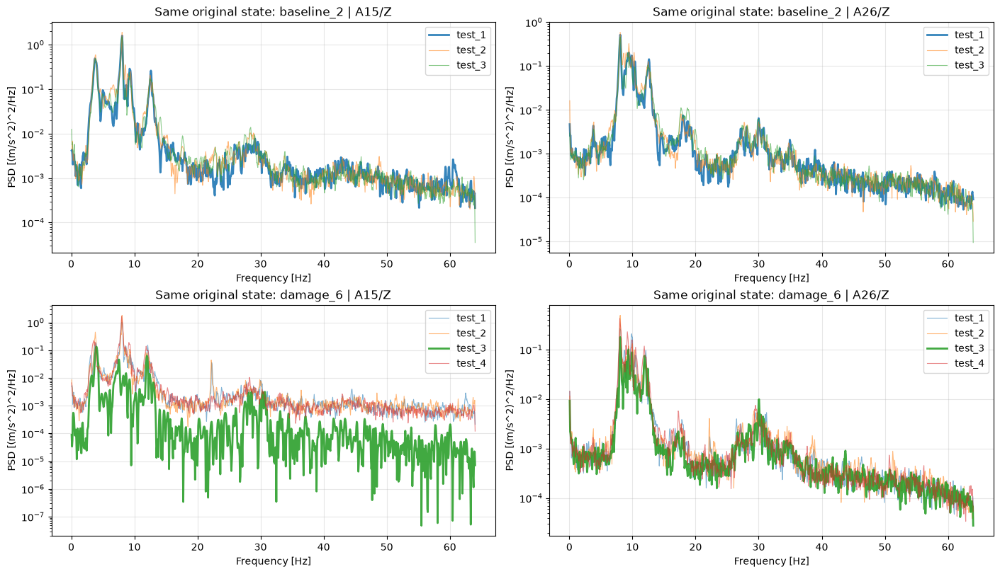

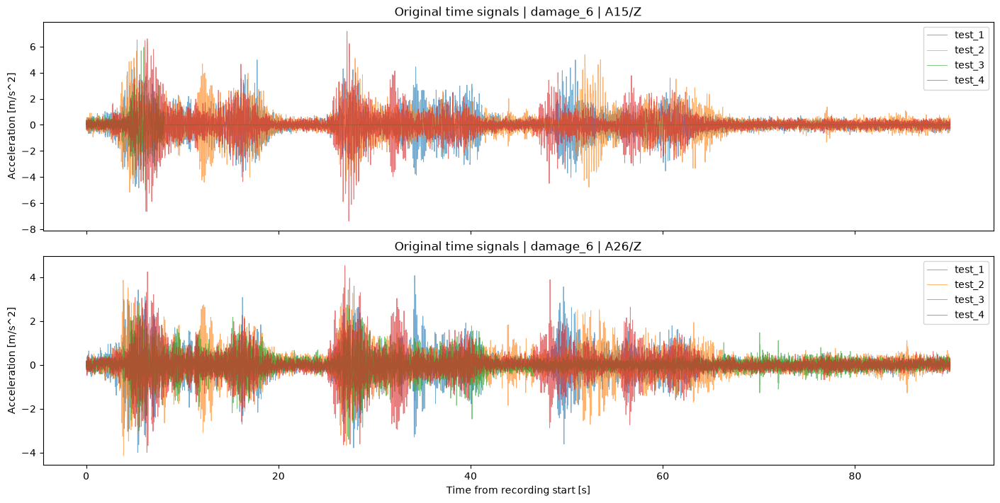

In [5]:
import json
with np.load(ROOT/"data/processed/all_acceleration_features.npz") as artifact:
    diagnostic_X=artifact["X"];diagnostic_y=artifact["y"]
    diagnostic_names=artifact["feature_names"].tolist()
    diagnostic_ids=artifact["record_ids"]
original_states=np.asarray([record.split('/')[0] for record in diagnostic_ids])
assert all(STATE_LABELS[state]==label for state,label in zip(original_states,diagnostic_y))
diagnostic_rows=[]
for i,record in enumerate(diagnostic_ids):
    if original_states[i] not in ("baseline_2","damage_6"):continue
    row={"recording":str(record),"original_state":str(original_states[i]),"binary_label":int(diagnostic_y[i])}
    for name in ["A15_z_rms","A15_z_kurtosis","A26_z_rms","A26_z_kurtosis"]:
        row[name]=float(diagnostic_X[i,diagnostic_names.index(name)])
    diagnostic_rows.append(row)
show_analysis_table(diagnostic_rows)

fig,axes=plt.subplots(2,2,figsize=(14,8),constrained_layout=True)
for row_index,state in enumerate(("baseline_2","damage_6")):
    with h5py.File(file_path,"r") as raw_file:
        tests=sorted(raw_file[state]["acceleration"])
    for column,sensor in enumerate(("A15","A26")):
        ax=axes[row_index,column]
        for test in tests:
            values,attrs=read_acceleration(file_path,state,test,sensor,"z")
            x=values.reshape(-1);fs=float(np.asarray(attrs["sample_rate"]).item())
            f,p=calculate_psd(x,fs)
            suspicious=(state=="damage_6" and test=="test_3") or (state=="baseline_2" and test=="test_1")
            ax.semilogy(f[1:],np.maximum(p[1:],np.finfo(float).tiny),label=test,lw=2 if suspicious else .8,alpha=.9 if suspicious else .55)
        ax.set_title(f"Same original state: {state} | {sensor}/Z")
        ax.set_xlabel("Frequency [Hz]");ax.set_ylabel("PSD [(m/s^2)^2/Hz]");ax.legend();ax.grid(alpha=.3)
plt.show()

fig,axes=plt.subplots(2,1,figsize=(14,7),sharex=True,constrained_layout=True)
for ax,sensor in zip(axes,("A15","A26")):
    for test in ("test_1","test_2","test_3","test_4"):
        values,attrs=read_acceleration(file_path,"damage_6",test,sensor,"z")
        x=values.reshape(-1);fs=float(np.asarray(attrs["sample_rate"]).item())
        ax.plot(np.arange(len(x))/fs,x,label=test,lw=.7,alpha=.6)
    ax.set_title(f"Original time signals | damage_6 | {sensor}/Z");ax.set_ylabel("Acceleration [m/s^2]");ax.legend()
axes[-1].set_xlabel("Time from recording start [s]");plt.show()


## 15. קרוס־ולידציה מקוננת לפי הקלטות
משווים שלוש אסטרטגיות באותם שלושה פיצולים חיצוניים: כל 2030 הפיצ׳רים, MFCC מכל 58 הערוצים (928 פיצ׳רים), וחיישן Z יחיד שנבחר מחדש בתוך האימון בלבד (16 פיצ׳רים).

בכל אימון חיצוני עושים 2-fold CV פנימי לבחירת C, ובאסטרטגיית חיישן יחיד גם לבחירת החיישן מבין 29 תקינים. האימון הפנימי בלבד לומד מילוי ותקנון. לאחר הבחירה מאמנים על כל האימון החיצוני ומנבאים את קבוצת הוולידציה החיצונית. A14 אינו מועמד בגלל הכשל הידוע. אין חלונות כדוגמאות מתויגות.

זהו ניסוי חקרני מתוקן מבחינת תהליך הבחירה, אך אינו מבטל את העובדה שכבר הסתכלנו על כל הדאטה. יש 25 הקלטות ו־6 בסיס בלבד, ללא גשר חיצוני. אין בחירה של האסטרטגיה לפי ציון פיצול בודד ואין טענה למודל מאומת לפריסה.


Completed outer fold: 1


Completed outer fold: 2


Completed outer fold: 3


strategy,fold,selected_sensor,C,inner_score,outer_balanced_accuracy,outer_baseline_recall,outer_damage_recall,outer_roc_auc
All features (2030),1,all,0.1000,0.9583,0.4286,0.0000,0.8571,0.8571
All MFCC (928),1,all,0.0100,0.7917,0.9286,1.0000,0.8571,1.0000
Inner-selected Z sensor (16),1,A01,0.1000,0.9167,0.6786,0.5000,0.8571,0.9286
All features (2030),2,all,0.1000,0.6250,0.3333,0.0000,0.6667,0.6667
All MFCC (928),2,all,0.0100,0.5833,0.6667,0.5000,0.8333,0.7500
Inner-selected Z sensor (16),2,A05,0.0100,0.7083,0.6667,0.5000,0.8333,0.7500
All features (2030),3,all,0.0100,0.7500,0.9167,1.0000,0.8333,1.0000
All MFCC (928),3,all,0.0100,0.8333,0.9167,1.0000,0.8333,0.9167
Inner-selected Z sensor (16),3,A26,0.0100,1.0000,0.9167,1.0000,0.8333,0.9167


strategy,outer_balanced_accuracy_mean,outer_balanced_accuracy_std,baseline_recall_mean,damage_recall_mean
All features (2030),0.5595,0.2555,0.3333,0.7857
All MFCC (928),0.8373,0.1208,0.8333,0.8413
Inner-selected Z sensor (16),0.7540,0.1151,0.6667,0.8413


strategy,original_state,binary_label,recordings,errors
All features (2030),baseline_1,0,3,2
All features (2030),baseline_2,0,3,2
All features (2030),damage_1,1,3,3
All features (2030),damage_2,1,3,0
All features (2030),damage_3,1,3,0
All features (2030),damage_4,1,3,0
All features (2030),damage_5,1,3,0
All features (2030),damage_6,1,4,1
All MFCC (928),baseline_1,0,3,0
All MFCC (928),baseline_2,0,3,1


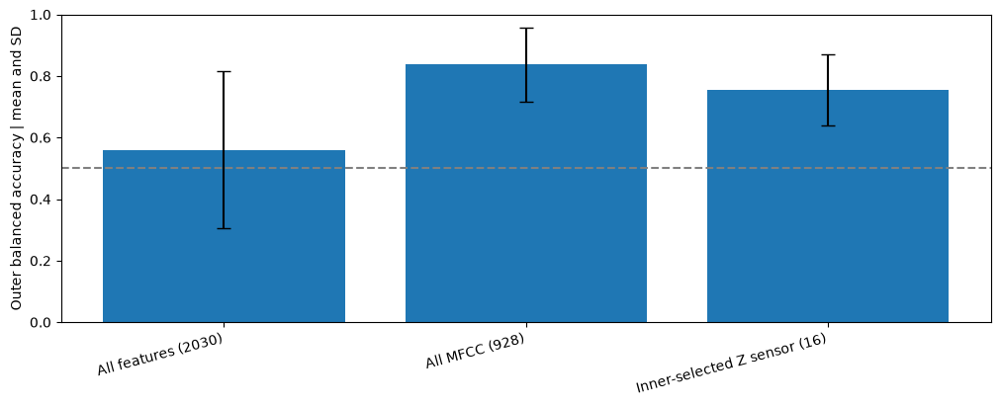

In [6]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold,GridSearchCV
from sklearn.metrics import balanced_accuracy_score,recall_score,roc_auc_score

def nested_pipeline():
    return Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
                     ("nonconstant",VarianceThreshold()),("scaler",StandardScaler()),
                     ("classifier",LogisticRegression(class_weight="balanced",max_iter=5000))])

outer_cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=42)
outer_partitions=list(outer_cv.split(diagnostic_X,diagnostic_y))
valid_sensors=sorted({n.split('_')[0] for n in diagnostic_names})
mfcc_columns=np.asarray([i for i,n in enumerate(diagnostic_names) if "_mfcc_" in n])
assert len(mfcc_columns)==928
z_sensor_columns={sensor:np.asarray([i for i,n in enumerate(diagnostic_names) if n.startswith(sensor+"_z_mfcc_")]) for sensor in valid_sensors}
assert all(len(columns)==16 for columns in z_sensor_columns.values())
strategies=["All features (2030)","All MFCC (928)","Inner-selected Z sensor (16)"]
nested_fold_rows=[];nested_predictions=[]
for fold,(train,validation) in enumerate(outer_partitions,start=1):
    assert set(diagnostic_ids[train]).isdisjoint(diagnostic_ids[validation])
    inner_cv=StratifiedKFold(n_splits=2,shuffle=True,random_state=50+fold)
    inner_partitions=list(inner_cv.split(diagnostic_X[train],diagnostic_y[train]))
    for strategy in strategies:
        if strategy=="All features (2030)":candidates=[("all",np.arange(diagnostic_X.shape[1]))]
        elif strategy=="All MFCC (928)":candidates=[("all",mfcc_columns)]
        else:candidates=sorted(z_sensor_columns.items())
        best_search=None;best_columns=None;best_sensor=None
        for sensor,columns in candidates:
            search=GridSearchCV(nested_pipeline(),{"classifier__C":[.01,.1,1.0]},
                                scoring="balanced_accuracy",cv=inner_partitions,n_jobs=1,error_score="raise")
            search.fit(diagnostic_X[train][:,columns],diagnostic_y[train])
            if best_search is None or search.best_score_>best_search.best_score_:
                best_search=search;best_columns=columns;best_sensor=sensor
        model=best_search.best_estimator_
        pred=model.predict(diagnostic_X[validation][:,best_columns])
        prob=model.predict_proba(diagnostic_X[validation][:,best_columns])[:,1]
        nested_fold_rows.append({"strategy":strategy,"fold":fold,"selected_sensor":best_sensor,
            "C":float(best_search.best_params_["classifier__C"]),"inner_score":float(best_search.best_score_),
            "outer_balanced_accuracy":float(balanced_accuracy_score(diagnostic_y[validation],pred)),
            "outer_baseline_recall":float(recall_score(diagnostic_y[validation],pred,pos_label=0,zero_division=0)),
            "outer_damage_recall":float(recall_score(diagnostic_y[validation],pred,pos_label=1,zero_division=0)),
            "outer_roc_auc":float(roc_auc_score(diagnostic_y[validation],prob))})
        for i,p,q in zip(validation,pred,prob):
            nested_predictions.append({"strategy":strategy,"fold":fold,"recording":str(diagnostic_ids[i]),
                "original_state":str(original_states[i]),"true_label":int(diagnostic_y[i]),
                "prediction":int(p),"damage_probability":float(q),"correct":bool(p==diagnostic_y[i])})
    print("Completed outer fold:",fold)
show_analysis_table(nested_fold_rows)
nested_summary=[]
for strategy in strategies:
    folds=[r for r in nested_fold_rows if r["strategy"]==strategy]
    values=np.asarray([r["outer_balanced_accuracy"] for r in folds])
    predictions=[r for r in nested_predictions if r["strategy"]==strategy]
    assert len(predictions)==25 and len({r["recording"] for r in predictions})==25
    nested_summary.append({"strategy":strategy,"outer_balanced_accuracy_mean":float(values.mean()),
        "outer_balanced_accuracy_std":float(values.std()),
        "baseline_recall_mean":float(np.mean([r["outer_baseline_recall"] for r in folds])),
        "damage_recall_mean":float(np.mean([r["outer_damage_recall"] for r in folds]))})
show_analysis_table(nested_summary)
state_error_rows=[]
for strategy in strategies:
    for state in STATE_LABELS:
        rows=[r for r in nested_predictions if r["strategy"]==strategy and r["original_state"]==state]
        state_error_rows.append({"strategy":strategy,"original_state":state,"binary_label":STATE_LABELS[state],
                                "recordings":len(rows),"errors":sum(not r["correct"] for r in rows)})
show_analysis_table(state_error_rows)
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
ax.bar(np.arange(3),[r["outer_balanced_accuracy_mean"] for r in nested_summary],
       yerr=[r["outer_balanced_accuracy_std"] for r in nested_summary],capsize=5)
ax.set_xticks(np.arange(3),strategies,rotation=15,ha="right");ax.set_ylim(0,1)
ax.axhline(.5,color="gray",ls="--");ax.set_ylabel("Outer balanced accuracy | mean and SD")
plt.show()
with (ROOT/"outputs/diagnostics_nested_report.json").open("w",encoding="utf-8") as stream:
    json.dump({"diagnostics":diagnostic_rows,"nested_summary":nested_summary,"folds":nested_fold_rows,
               "predictions":nested_predictions,"errors_by_original_state":state_error_rows,
               "warning":"Exploratory nested validation on previously inspected same-bridge recordings"},stream,indent=2)


## 16. אותם 928 פיצ׳רי MFCC — השוואת מודלים ובדיקת אוברפיט
משווים Logistic L2, SVM RBF, Random Forest, Extra Trees ו־Histogram Gradient Boosting באותם שלושה פיצולים חיצוניים מהניסוי המקונן הקודם (seed=42). כל שורה היא הקלטה שלמה. לכל מודל אותם 928 פיצ׳רים מכל 58 הערוצים, ללא A14. אף חיישן או פיצ׳ר לא נבחרים לפי הוולידציה החיצונית.

בחירת הפרמטרים נעשית ב־2-fold CV בתוך כל אימון חיצוני בלבד. Pipeline לומד מילוי, הסרת פיצ׳רים קבועים ותקנון בכל אימון פנימי. האימון החיצוני והוולידציה שלו נפרדים. ההגדרות מוגבלות ומורכבות העצים מרוסנת. רגרסיה לוגיסטית משתמשת באותו טווח C מהניסוי הקודם. הוולידציה החיצונית אינה משמשת לכוונון הפרמטרים או הסף (0.5, וב־SVM סף decision_function=0).

אבחון אוברפיט: מודדים balanced accuracy באימון החיצוני ובוולידציה החיצונית, ובאימון/ולידציה פנימיים. פער גדול ועקבי או פיזור חיצוני גדול הם סימני סיכון, לא מבחן המוכיח נוכחות או היעדר אוברפיט. שישה מצבי בסיס בלבד, פיצולים קטנים ודאטה שכבר נחקר אינם מאפשרים להוכיח שאין אוברפיט או שהמודל מכליל לגשר חדש. בחירת המודל המנצח מבין כמה מודלים מוסיפה אופטימיות; עדיין נדרשות הקלטות חדשות להערכה סופית.


Completed model comparison, outer fold 1


Completed model comparison, outer fold 2


Completed model comparison, outer fold 3


model,train_balanced_accuracy_mean,outer_balanced_accuracy_mean,outer_balanced_accuracy_std,train_outer_gap_mean,inner_train_mean,inner_validation_mean,baseline_recall_mean,damage_recall_mean
Logistic L2,1.0000,0.8373,0.1208,0.1627,1.0000,0.7361,0.8333,0.8413
Random Forest,1.0000,0.7778,0.1039,0.2222,1.0000,0.6944,0.6667,0.8889
Histogram Boosting,1.0000,0.6667,0.2722,0.3333,1.0000,0.5714,0.5000,0.8333
SVM RBF,0.9722,0.6429,0.0424,0.3294,0.9028,0.7361,0.5000,0.7857
Extra Trees,0.9861,0.5556,0.0786,0.4306,0.9762,0.7083,0.1667,0.9444


model,fold,parameters,train_balanced_accuracy,outer_balanced_accuracy,train_outer_gap,inner_train_balanced_accuracy,inner_validation_balanced_accuracy,inner_gap,baseline_recall,damage_recall,outer_roc_auc
Logistic L2,1,{'classifier__C': 0.01},1.0000,0.9286,0.0714,1.0000,0.7917,0.2083,1.0000,0.8571,1.0000
SVM RBF,1,"{'classifier__C': 0.1, 'classifier__gamma': 'scale'}",0.9167,0.6786,0.2381,0.9583,0.8333,0.1250,0.5000,0.8571,0.7143
Random Forest,1,"{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2}",1.0000,0.7500,0.2500,1.0000,0.6667,0.3333,0.5000,1.0000,1.0000
Extra Trees,1,"{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 4}",0.9583,0.5000,0.4583,1.0000,0.7500,0.2500,0.0000,1.0000,0.8571
Histogram Boosting,1,"{'classifier__l2_regularization': 0.1, 'classifier__max_leaf_nodes': 3, 'classifier__min_samples_leaf': 2}",1.0000,1.0000,0.0000,1.0000,0.5417,0.4583,1.0000,1.0000,1.0000
Logistic L2,2,{'classifier__C': 0.01},1.0000,0.6667,0.3333,1.0000,0.5833,0.4167,0.5000,0.8333,0.7500
SVM RBF,2,"{'classifier__C': 0.1, 'classifier__gamma': 'scale'}",1.0000,0.6667,0.3333,0.7500,0.5000,0.2500,0.5000,0.8333,0.7500
Random Forest,2,"{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2}",1.0000,0.6667,0.3333,1.0000,0.5833,0.4167,0.5000,0.8333,0.7500
Extra Trees,2,"{'classifier__max_depth': 2, 'classifier__min_samples_leaf': 2}",1.0000,0.5000,0.5000,1.0000,0.5000,0.5000,0.0000,1.0000,0.6667
Histogram Boosting,2,"{'classifier__l2_regularization': 0.1, 'classifier__max_leaf_nodes': 3, 'classifier__min_samples_leaf': 2}",1.0000,0.6667,0.3333,1.0000,0.6250,0.3750,0.5000,0.8333,0.6667


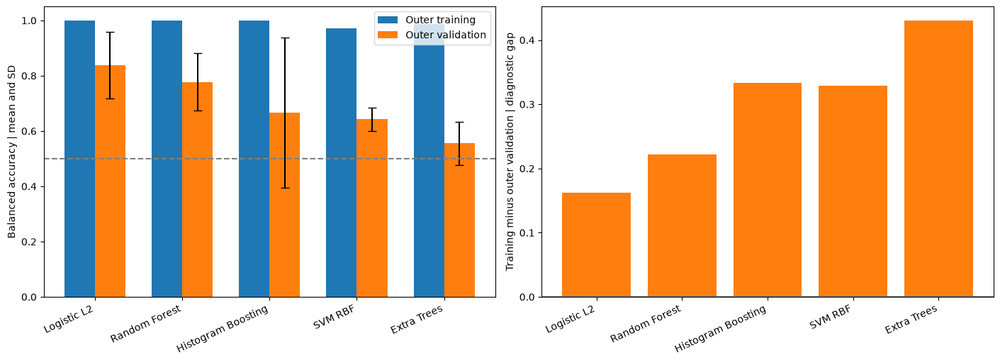

In [3]:
import json
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold,GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score,recall_score,roc_auc_score,accuracy_score,confusion_matrix

with np.load(ROOT/"data/processed/all_acceleration_features.npz") as artifact:
    model_source_X=artifact["X"];model_y=artifact["y"]
    model_names=artifact["feature_names"].tolist();model_record_ids=artifact["record_ids"]
model_mfcc_columns=np.asarray([i for i,name in enumerate(model_names) if "_mfcc_" in name])
model_X=model_source_X[:,model_mfcc_columns]
assert model_X.shape==(25,928) and len(set(model_record_ids))==25
assert np.isfinite(model_X).all()
outer_model_splits=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=42).split(model_X,model_y))
model_specs=[
    ("Logistic L2",LogisticRegression(class_weight="balanced",max_iter=5000),
     {"classifier__C":[.01,.1,1.0]}),
    ("SVM RBF",SVC(kernel="rbf",class_weight="balanced"),
     {"classifier__C":[.1,1.0,10.0],"classifier__gamma":["scale",.0001]}),
    ("Random Forest",RandomForestClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=1),
     {"classifier__max_depth":[2,4],"classifier__min_samples_leaf":[2,4]}),
    ("Extra Trees",ExtraTreesClassifier(n_estimators=200,class_weight="balanced",random_state=42,n_jobs=1),
     {"classifier__max_depth":[2,4],"classifier__min_samples_leaf":[2,4]}),
    ("Histogram Boosting",HistGradientBoostingClassifier(max_iter=100,learning_rate=.05,early_stopping=False,class_weight="balanced",random_state=42),
     {"classifier__max_leaf_nodes":[3,7],"classifier__min_samples_leaf":[2,5],"classifier__l2_regularization":[.1,1.0]}),
]
mfcc_model_folds=[];mfcc_model_predictions=[]
for fold,(train,validation) in enumerate(outer_model_splits,start=1):
    assert set(model_record_ids[train]).isdisjoint(model_record_ids[validation])
    inner_splits=list(StratifiedKFold(n_splits=2,shuffle=True,random_state=50+fold).split(model_X[train],model_y[train]))
    for name,estimator,grid in model_specs:
        pipeline=Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
            ("nonconstant",VarianceThreshold()),("scaler",StandardScaler()),("classifier",estimator)])
        search=GridSearchCV(pipeline,grid,scoring="balanced_accuracy",cv=inner_splits,
                           return_train_score=True,n_jobs=1,error_score="raise")
        search.fit(model_X[train],model_y[train]);model=search.best_estimator_
        training_pred=model.predict(model_X[train]);validation_pred=model.predict(model_X[validation])
        validation_score=model.decision_function(model_X[validation]) if hasattr(model,"decision_function") else model.predict_proba(model_X[validation])[:,1]
        train_ba=float(balanced_accuracy_score(model_y[train],training_pred))
        outer_ba=float(balanced_accuracy_score(model_y[validation],validation_pred))
        best_index=search.best_index_
        inner_train=float(search.cv_results_["mean_train_score"][best_index])
        inner_validation=float(search.cv_results_["mean_test_score"][best_index])
        mfcc_model_folds.append({"model":name,"fold":fold,"parameters":search.best_params_,
            "train_balanced_accuracy":train_ba,"outer_balanced_accuracy":outer_ba,
            "train_outer_gap":train_ba-outer_ba,"inner_train_balanced_accuracy":inner_train,
            "inner_validation_balanced_accuracy":inner_validation,"inner_gap":inner_train-inner_validation,
            "baseline_recall":float(recall_score(model_y[validation],validation_pred,pos_label=0,zero_division=0)),
            "damage_recall":float(recall_score(model_y[validation],validation_pred,pos_label=1,zero_division=0)),
            "outer_roc_auc":float(roc_auc_score(model_y[validation],validation_score))})
        for i,p,score in zip(validation,validation_pred,validation_score):
            mfcc_model_predictions.append({"model":name,"fold":fold,"recording":str(model_record_ids[i]),
                "original_state":str(model_record_ids[i]).split('/')[0],"true_label":int(model_y[i]),
                "prediction":int(p),"decision_score":float(score)})
    print("Completed model comparison, outer fold",fold)

mfcc_model_summary=[]
for name,_,_ in model_specs:
    rows=[r for r in mfcc_model_folds if r["model"]==name]
    values=np.asarray([r["outer_balanced_accuracy"] for r in rows])
    predictions=[r for r in mfcc_model_predictions if r["model"]==name]
    assert len(predictions)==25 and len({r["recording"] for r in predictions})==25
    mfcc_model_summary.append({"model":name,
        "train_balanced_accuracy_mean":float(np.mean([r["train_balanced_accuracy"] for r in rows])),
        "outer_balanced_accuracy_mean":float(values.mean()),"outer_balanced_accuracy_std":float(values.std()),
        "train_outer_gap_mean":float(np.mean([r["train_outer_gap"] for r in rows])),
        "inner_train_mean":float(np.mean([r["inner_train_balanced_accuracy"] for r in rows])),
        "inner_validation_mean":float(np.mean([r["inner_validation_balanced_accuracy"] for r in rows])),
        "baseline_recall_mean":float(np.mean([r["baseline_recall"] for r in rows])),
        "damage_recall_mean":float(np.mean([r["damage_recall"] for r in rows]))})
mfcc_model_summary.sort(key=lambda r:r["outer_balanced_accuracy_mean"],reverse=True)
show_analysis_table(mfcc_model_summary)
show_analysis_table(mfcc_model_folds)

fig,axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
positions=np.arange(len(mfcc_model_summary));width=.35
axes[0].bar(positions-width/2,[r["train_balanced_accuracy_mean"] for r in mfcc_model_summary],width,label="Outer training")
axes[0].bar(positions+width/2,[r["outer_balanced_accuracy_mean"] for r in mfcc_model_summary],width,
            yerr=[r["outer_balanced_accuracy_std"] for r in mfcc_model_summary],capsize=4,label="Outer validation")
axes[0].set_ylabel("Balanced accuracy | mean and SD");axes[0].set_ylim(0,1.05)
axes[0].axhline(.5,color="gray",ls="--");axes[0].legend()
axes[1].bar(positions,[r["train_outer_gap_mean"] for r in mfcc_model_summary],color="tab:orange")
axes[1].axhline(0,color="gray");axes[1].set_ylabel("Training minus outer validation | diagnostic gap")
for ax in axes:ax.set_xticks(positions,[r["model"] for r in mfcc_model_summary],rotation=25,ha="right")
plt.show()

previous_nested=json.loads((ROOT/"outputs/diagnostics_nested_report.json").read_text())
expected=next(r for r in previous_nested["nested_summary"] if r["strategy"]=="All MFCC (928)")["outer_balanced_accuracy_mean"]
actual=next(r for r in mfcc_model_summary if r["model"]=="Logistic L2")["outer_balanced_accuracy_mean"]
assert np.isclose(actual,expected),"Reference model no longer matches previous splits"
with (ROOT/"outputs/mfcc_models_overfit_report.json").open("w",encoding="utf-8") as stream:
    json.dump({"features":928,"recordings":25,"summary":mfcc_model_summary,"folds":mfcc_model_folds,
        "predictions":mfcc_model_predictions,"warning":"Cannot establish absence of overfitting with 25 previously inspected recordings; no external test"},stream,indent=2)


## 17. Precision–Recall comparison on held-out recordings

Average Precision (AP) summarizes the precision–recall curve without trapezoidal interpolation. Report the mean and standard deviation across the same three outer folds, using their held-out scores. Hyperparameters were previously selected using balanced accuracy; this is an additional evaluation, not AP-specific tuning.

Damage (1) is the majority: 19/25 = 0.76. Baseline (0) is the minority: 6/25 = 0.24. Evaluate both directions by reversing the score for class 0. The primary comparison is mean fold AP; pooling scores from separately fitted models can distort rankings because score scales differ. This does not establish generalization to unseen damage states or bridges, or absence of overfitting.


model,damage_AP_mean,damage_AP_SD,baseline_AP_mean,baseline_AP_SD,damage_trapezoidal_PR_AUC_mean
Logistic L2,0.9689,0.0288,0.7778,0.2079,0.9663
Random Forest,0.9689,0.0288,0.7778,0.2079,0.9663
Extra Trees,0.9425,0.0239,0.5833,0.1361,0.9379
SVM RBF,0.9343,0.0103,0.5667,0.1312,0.9288
Histogram Boosting,0.8380,0.1254,0.5417,0.3281,0.8958


model,fold,damage_prevalence,damage_AP,damage_trapezoidal_PR_AUC,baseline_AP,baseline_trapezoidal_PR_AUC
Extra Trees,1,0.7778,0.9683,0.9663,0.5833,0.4167
Extra Trees,2,0.7500,0.9107,0.9038,0.4167,0.2917
Extra Trees,3,0.7500,0.9484,0.9437,0.7500,0.7083
Histogram Boosting,1,0.7778,1.0000,1.0000,1.0000,1.0000
Histogram Boosting,2,0.7500,0.8194,0.8958,0.3750,0.5625
Histogram Boosting,3,0.7500,0.6944,0.7917,0.2500,0.1250
Logistic L2,1,0.7778,1.0000,1.0000,1.0000,1.0000
Logistic L2,2,0.7500,0.9306,0.9248,0.5000,0.3333
Logistic L2,3,0.7500,0.9762,0.9742,0.8333,0.7917
Random Forest,1,0.7778,1.0000,1.0000,1.0000,1.0000


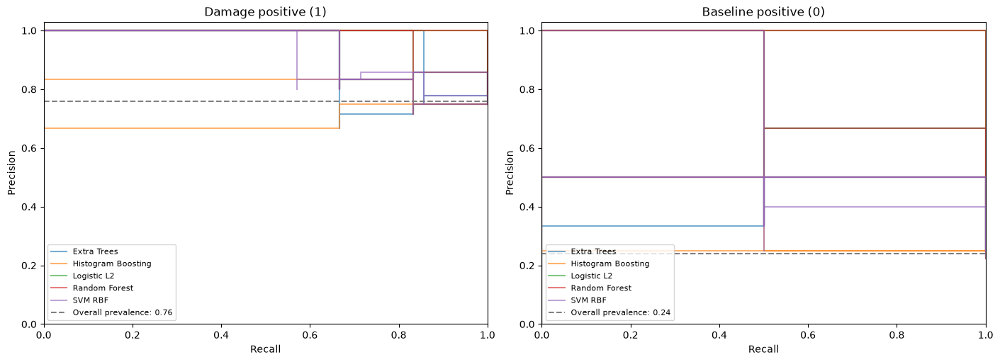

5640

In [3]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve, auc

pr_source = json.loads((ROOT / "outputs/mfcc_models_overfit_report.json").read_text())
pr_predictions = pr_source["predictions"]
pr_folds = []
pr_summary = []
pr_models = sorted({r["model"] for r in pr_predictions})
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for model_index, name in enumerate(pr_models):
    color = f"C{model_index}"
    for fold in (1, 2, 3):
        rows = [r for r in pr_predictions if r["model"] == name and r["fold"] == fold]
        y = np.asarray([r["true_label"] for r in rows])
        scores = np.asarray([r["decision_score"] for r in rows])
        assert len(np.unique(y)) == 2 and np.isfinite(scores).all()
        result = {"model": name, "fold": fold, "damage_prevalence": float(y.mean())}
        for axis, label, positive, score in zip(axes, ("damage", "baseline"), (y, 1-y), (scores, -scores)):
            precision, recall, _ = precision_recall_curve(positive, score)
            result[label + "_AP"] = float(average_precision_score(positive, score))
            result[label + "_trapezoidal_PR_AUC"] = float(auc(recall, precision))
            axis.step(recall, precision, where="post", color=color, alpha=.6,
                      label=name if fold == 1 else None)
        pr_folds.append(result)
    selected = [r for r in pr_folds if r["model"] == name]
    pr_summary.append({"model": name,
        "damage_AP_mean": float(np.mean([r["damage_AP"] for r in selected])),
        "damage_AP_SD": float(np.std([r["damage_AP"] for r in selected])),
        "baseline_AP_mean": float(np.mean([r["baseline_AP"] for r in selected])),
        "baseline_AP_SD": float(np.std([r["baseline_AP"] for r in selected])),
        "damage_trapezoidal_PR_AUC_mean": float(np.mean([r["damage_trapezoidal_PR_AUC"] for r in selected]))})
pr_summary.sort(key=lambda r: r["damage_AP_mean"], reverse=True)
show_analysis_table(pr_summary)
show_analysis_table(pr_folds)
for axis, title, prevalence in zip(axes, ("Damage positive (1)", "Baseline positive (0)"), (.76, .24)):
    axis.axhline(prevalence, color="gray", linestyle="--", label=f"Overall prevalence: {prevalence:.2f}")
    axis.set(title=title, xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03))
    axis.legend(fontsize=8)
plt.show()
(ROOT / "outputs/mfcc_pr_auc_report.json").write_text(json.dumps({"summary": pr_summary,
    "folds": pr_folds, "metric": "Mean outer-fold Average Precision; trapezoidal PR-AUC also reported",
    "tuning_metric": "balanced_accuracy", "damage_prevalence": .76, "baseline_prevalence": .24}, indent=2), encoding="utf-8")


## 18. Corrected evaluation: hold out entire experimental states

This stage supersedes stages 16–17 for assessing unseen experimental states. All recordings of a state stay together. There are only two baseline states: two outer folds are feasible with both labels in training and validation; nested grouped tuning with both labels in every inner partition is not feasible after holding out one baseline state. Use explicit conservative fixed parameters, not GridSearchCV. These parameters and the MFCC family were informed by earlier exploratory work, so these results are still exploratory, not an untouched final test.

Evaluate all 20 complementary allocations of the six damage states (three per side), anchoring baseline_1 on one side and baseline_2 on the other. Each allocation has two folds; reuse the same allocations for all models. Repetition does not create independent samples or confidence intervals. Per-allocation out-of-fold metrics cover all 25 recordings; their spread measures split sensitivity. AP is additionally computed within each fold to avoid pooling scores with different scales. Include minority-baseline AP. Each preprocessing pipeline is fitted only on its training states. There is one bridge, so this cannot validate prediction on a new bridge. Original states may also share experimental history; state grouping does not establish full physical independence.


C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

...

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\project_ML\BridgePulse\.venv\Lib\site-packages\sklearn\utils\parallel.py:144

Completed grouped allocations 20 /20


model,OOF_BA_mean,OOF_BA_split_SD,OOF_BA_min,OOF_BA_max,train_BA_mean,train_validation_gap_mean,damage_AP_mean,baseline_AP_mean,baseline_recall_mean,damage_recall_mean
Random Forest,0.6535,0.0711,0.5088,0.7544,1.0000,0.3471,0.9409,0.6113,0.5333,0.7737
Logistic L2,0.6399,0.0899,0.5088,0.8947,1.0000,0.3618,0.9399,0.5812,0.5667,0.7132
Extra Trees,0.5998,0.0808,0.4474,0.7544,0.9961,0.3974,0.9273,0.5783,0.3917,0.8079
SVM RBF,0.5261,0.0699,0.4211,0.6711,0.9936,0.4696,0.8965,0.5088,0.1917,0.8605
Histogram Boosting,0.5200,0.0908,0.3158,0.6974,1.0000,0.4822,0.8711,0.4531,0.3083,0.7316


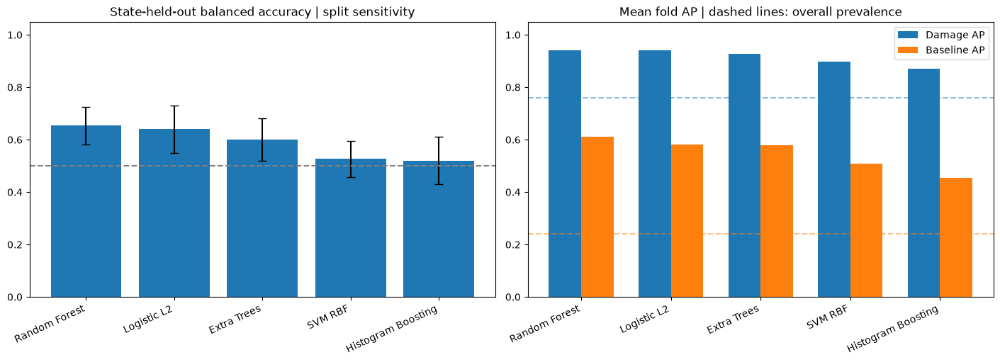

635507

In [3]:
import json
import itertools
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import balanced_accuracy_score, average_precision_score, recall_score

with np.load(ROOT / "data/processed/all_acceleration_features.npz") as artifact:
    grouped_names = artifact["feature_names"].astype(str)
    grouped_X = artifact["X"][:, [i for i,n in enumerate(grouped_names) if "_mfcc_" in n]]
    grouped_y = artifact["y"]
    grouped_ids = artifact["record_ids"].astype(str)
grouped_states = np.asarray([r.split('/')[0] for r in grouped_ids])
assert grouped_X.shape == (25,928) and len(set(grouped_ids)) == 25
assert np.isfinite(grouped_X).all()
grouped_specs = {
    "Logistic L2": LogisticRegression(C=.01, class_weight="balanced", max_iter=5000),
    "SVM RBF": SVC(C=.1, gamma="scale", class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200,max_depth=2,min_samples_leaf=2,class_weight="balanced",random_state=42,n_jobs=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200,max_depth=2,min_samples_leaf=4,class_weight="balanced",random_state=42,n_jobs=1),
    "Histogram Boosting": HistGradientBoostingClassifier(max_iter=100,learning_rate=.05,max_leaf_nodes=3,min_samples_leaf=5,l2_regularization=1.,class_weight="balanced",early_stopping=False,random_state=42),
}
damage_states = [f"damage_{i}" for i in range(1,7)]
grouped_folds, grouped_allocations, grouped_predictions = [], [], []
for allocation, damages in enumerate(itertools.combinations(damage_states,3),1):
    side_a = {"baseline_1", *damages}
    side_b = set(grouped_states) - side_a
    for name, estimator in grouped_specs.items():
        oof = np.empty_like(grouped_y)
        for fold, validation_states in enumerate((side_a,side_b),1):
            validation = np.flatnonzero(np.isin(grouped_states,list(validation_states)))
            train = np.flatnonzero(~np.isin(grouped_states,list(validation_states)))
            assert set(grouped_states[train]).isdisjoint(grouped_states[validation])
            assert set(grouped_ids[train]).isdisjoint(grouped_ids[validation])
            assert len(np.unique(grouped_y[train])) == len(np.unique(grouped_y[validation])) == 2
            pipeline = Pipeline([("imputer",SimpleImputer(strategy="median",keep_empty_features=True)),
                ("nonconstant",VarianceThreshold()),("scaler",StandardScaler()),("classifier",clone(estimator))])
            pipeline.fit(grouped_X[train],grouped_y[train])
            training_selected = pipeline["nonconstant"].transform(pipeline["imputer"].transform(grouped_X[train]))
            assert np.allclose(pipeline["scaler"].mean_,training_selected.mean(axis=0))
            assert int(pipeline["scaler"].n_samples_seen_) == len(train)
            predicted = pipeline.predict(grouped_X[validation]); oof[validation] = predicted
            scores = pipeline.decision_function(grouped_X[validation]) if hasattr(pipeline,"decision_function") else pipeline.predict_proba(grouped_X[validation])[:,1]
            train_ba = float(balanced_accuracy_score(grouped_y[train],pipeline.predict(grouped_X[train])))
            val_ba = float(balanced_accuracy_score(grouped_y[validation],predicted))
            grouped_folds.append({"allocation":allocation,"fold":fold,"model":name,
                "train_states":sorted(set(grouped_states[train])),"validation_states":sorted(validation_states),
                "train_BA":train_ba,"validation_BA":val_ba,"gap":train_ba-val_ba,
                "damage_AP":float(average_precision_score(grouped_y[validation],scores)),
                "baseline_AP":float(average_precision_score(1-grouped_y[validation],-scores)),
                "damage_prevalence":float(grouped_y[validation].mean())})
            for i,p,s in zip(validation,predicted,scores):
                grouped_predictions.append({"allocation":allocation,"fold":fold,"model":name,
                    "recording":str(grouped_ids[i]),"true_label":int(grouped_y[i]),"prediction":int(p),"score":float(s)})
        grouped_allocations.append({"allocation":allocation,"model":name,
            "OOF_BA":float(balanced_accuracy_score(grouped_y,oof)),
            "baseline_recall":float(recall_score(grouped_y,oof,pos_label=0)),
            "damage_recall":float(recall_score(grouped_y,oof,pos_label=1))})
    if allocation % 5 == 0: print("Completed grouped allocations",allocation,"/20")
grouped_summary=[]
for name in grouped_specs:
    folds=[r for r in grouped_folds if r["model"]==name]
    allocations=[r for r in grouped_allocations if r["model"]==name]
    ba=np.asarray([r["OOF_BA"] for r in allocations])
    grouped_summary.append({"model":name,"OOF_BA_mean":float(ba.mean()),"OOF_BA_split_SD":float(ba.std()),
        "OOF_BA_min":float(ba.min()),"OOF_BA_max":float(ba.max()),
        "train_BA_mean":float(np.mean([r["train_BA"] for r in folds])),
        "train_validation_gap_mean":float(np.mean([r["gap"] for r in folds])),
        "damage_AP_mean":float(np.mean([r["damage_AP"] for r in folds])),
        "baseline_AP_mean":float(np.mean([r["baseline_AP"] for r in folds])),
        "baseline_recall_mean":float(np.mean([r["baseline_recall"] for r in allocations])),
        "damage_recall_mean":float(np.mean([r["damage_recall"] for r in allocations]))})
grouped_summary.sort(key=lambda r:r["OOF_BA_mean"],reverse=True)
show_analysis_table(grouped_summary)
fig, axes=plt.subplots(1,2,figsize=(14,5),constrained_layout=True)
positions=np.arange(len(grouped_summary)); labels=[r["model"] for r in grouped_summary]
axes[0].bar(positions,[r["OOF_BA_mean"] for r in grouped_summary],yerr=[r["OOF_BA_split_SD"] for r in grouped_summary],capsize=4)
axes[0].axhline(.5,color="gray",ls="--");axes[0].set_title("State-held-out balanced accuracy | split sensitivity")
axes[1].bar(positions-.18,[r["damage_AP_mean"] for r in grouped_summary],.36,label="Damage AP")
axes[1].bar(positions+.18,[r["baseline_AP_mean"] for r in grouped_summary],.36,label="Baseline AP")
axes[1].axhline(.76,color="C0",ls="--",alpha=.5);axes[1].axhline(.24,color="C1",ls="--",alpha=.5)
axes[1].set_title("Mean fold AP | dashed lines: overall prevalence");axes[1].legend()
for ax in axes: ax.set_xticks(positions,labels,rotation=25,ha="right");ax.set_ylim(0,1.05)
plt.show()
(ROOT/"outputs/grouped_mfcc_models_report.json").write_text(json.dumps({"summary":grouped_summary,
    "folds":grouped_folds,"allocations":grouped_allocations,"predictions":grouped_predictions,
    "fixed_parameters":{name:est.get_params() for name,est in grouped_specs.items()},
    "normalization_train_only_checks_passed":True,"group_overlap_checks_passed":True,
    "limitations":"Exploratory, fixed parameters; 8 states, 2 baseline states, 1 bridge. Repeated splits are dependent. No independent final test."},indent=2),encoding="utf-8")


## 19. New feature families: LFCC and Haar wavelet energies

Compare fixed Logistic L2 and shallow Random Forest using the same 20 state-grouped allocations as stage 18. Results remain exploratory. Haar relative energies add temporal-scale information without creating separately labeled windows. LFCC uses linear frequency filters. Raw H5 is unchanged. The full reusable implementation is in `scripts/new_feature_experiment.py`.

In [ ]:
import sys
if str(ROOT / "scripts") not in sys.path: sys.path.insert(0,str(ROOT / "scripts"))
from new_feature_experiment import run_experiment
new_feature_report = run_experiment()
show_analysis_table(new_feature_report["summary"])

[
  {
    "family": "MFCC",
    "model": "Random Forest",
    "features": 928,
    "BA_mean": 0.6535087719298246,
    "BA_split_SD": 0.07110134782161207,
    "train_BA": 1.0,
    "gap": 0.34708333333333335,
    "damage_AP": 0.9409373774373775,
    "baseline_AP": 0.6112500000000001
  },
  {
    "family": "MFCC + Haar",
    "model": "Random Forest",
    "features": 1392,
    "BA_mean": 0.6480263157894737,
    "BA_split_SD": 0.08246168094487048,
    "train_BA": 1.0,
    "gap": 0.35291666666666666,
    "damage_AP": 0.9336515105265107,
    "baseline_AP": 0.6249702380952382
  },
  {
    "family": "LFCC",
    "model": "Logistic L2",
    "features": 928,
    "BA_mean": 0.6453947368421052,
    "BA_split_SD": 0.08584931137085557,
    "train_BA": 1.0,
    "gap": 0.35625000000000007,
    "damage_AP": 0.9409714490756158,
    "baseline_AP": 0.5814186507936508
  },
  {
    "family": "LFCC",
    "model": "Random Forest",
    "features": 928,
    "BA_mean": 0.6425438596491228,
    "BA_split_SD": 0.0832

## 20. Training-only SHAP feature selection

Shallow Random Forest on MFCC. For each state-separated training set, rank by mean absolute damage-class TreeSHAP on training rows, refit with 10/25/50/100 features and evaluate on held-out states. Compare with all 928 features. Trees require no normalization. Fixed counts are experimental comparisons, not an independently validated choice of best count. SHAP is model attribution, not causality; correlated features may share credit. Forty folds reuse eight states, so split variability is not a confidence interval. See `scripts/shap_feature_selection.py` for implementation.

[
  {
    "features": 10,
    "BA_mean": 0.6425438596491228,
    "BA_split_SD": 0.05586727720551315,
    "paired_BA_change_vs_all": -0.010964912280701738,
    "train_BA": 1.0,
    "gap": 0.35833333333333334,
    "damage_AP": 0.9345823736448736,
    "baseline_AP": 0.6073015873015872
  },
  {
    "features": 25,
    "BA_mean": 0.6322368421052632,
    "BA_split_SD": 0.09350723929819334,
    "paired_BA_change_vs_all": -0.02127192982456138,
    "train_BA": 1.0,
    "gap": 0.3686111111111111,
    "damage_AP": 0.9266003518086852,
    "baseline_AP": 0.5956069624819624
  },
  {
    "features": 50,
    "BA_mean": 0.631140350877193,
    "BA_split_SD": 0.09760028501792492,
    "paired_BA_change_vs_all": -0.022368421052631572,
    "train_BA": 1.0,
    "gap": 0.3693055555555555,
    "damage_AP": 0.9230694745069744,
    "baseline_AP": 0.5673322510822512
  },
  {
    "features": 100,
    "BA_mean": 0.6199561403508771,
    "BA_split_SD": 0.09758426960194848,
    "paired_BA_change_vs_all": -0.0335526315

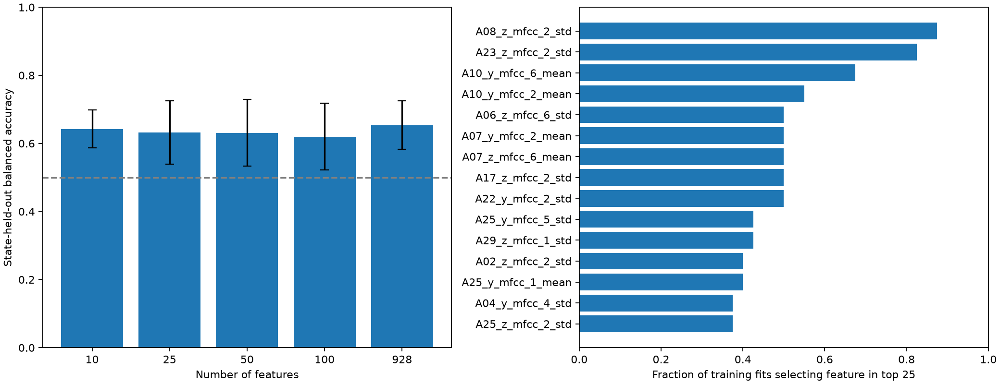

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from shap_feature_selection import run_shap_experiment
shap_selection_report=run_shap_experiment()
show_analysis_table(shap_selection_report["summary"])
show_analysis_table(shap_selection_report["top25_selection_frequency"][:15])
from IPython.display import Image,display
display(Image(filename=str(ROOT/"outputs/shap_selection.png")))

## 21. Problematic experimental states: descriptive feature analysis

Damage_1 and baseline_2 have the weakest held-out identification. Report per-state accuracy across repeated state-separated splits, fixed physical summaries (median across channels per recording), and exploratory damage_1-versus-rest feature rankings. Only three damage_1 recordings exist. Rankings across 2030 features are post-hoc and can overfit; descriptive AUC is not a test score or statistical significance. No model is changed using these findings.

In [ ]:
import json
problem_state_report=json.loads((ROOT/"outputs/problem_state_features_report.json").read_text())
show_analysis_table(problem_state_report["state_accuracy"])
show_analysis_table(problem_state_report["damage_1_aggregate_channel_summaries"])
show_analysis_table(problem_state_report["exploratory_top_features"][:10])

{
  "state_accuracy": [
    {
      "model": "Random Forest",
      "state": "baseline_1",
      "correct_fraction_across_splits": 0.7833333333333333
    },
    {
      "model": "Random Forest",
      "state": "baseline_2",
      "correct_fraction_across_splits": 0.2833333333333333
    },
    {
      "model": "Random Forest",
      "state": "damage_1",
      "correct_fraction_across_splits": 0.2
    },
    {
      "model": "Random Forest",
      "state": "damage_2",
      "correct_fraction_across_splits": 0.9166666666666666
    },
    {
      "model": "Random Forest",
      "state": "damage_3",
      "correct_fraction_across_splits": 0.8
    },
    {
      "model": "Random Forest",
      "state": "damage_4",
      "correct_fraction_across_splits": 0.95
    },
    {
      "model": "Random Forest",
      "state": "damage_5",
      "correct_fraction_across_splits": 1.0
    },
    {
      "model": "Random Forest",
      "state": "damage_6",
      "correct_fraction_across_splits": 0.775
   

## 22. Raw-signal checks: A06/Y and A18/Z

Inspect all recording PSDs and the three raw damage_1 traces. Recompute the proposed features, then check sensitivity to trimming five seconds from each end and to non-overlapping 20-second frames. Frames are descriptive, not independently labeled examples; event times across recordings are not assumed aligned. These are post-hoc checks and do not establish a physical damage cause.

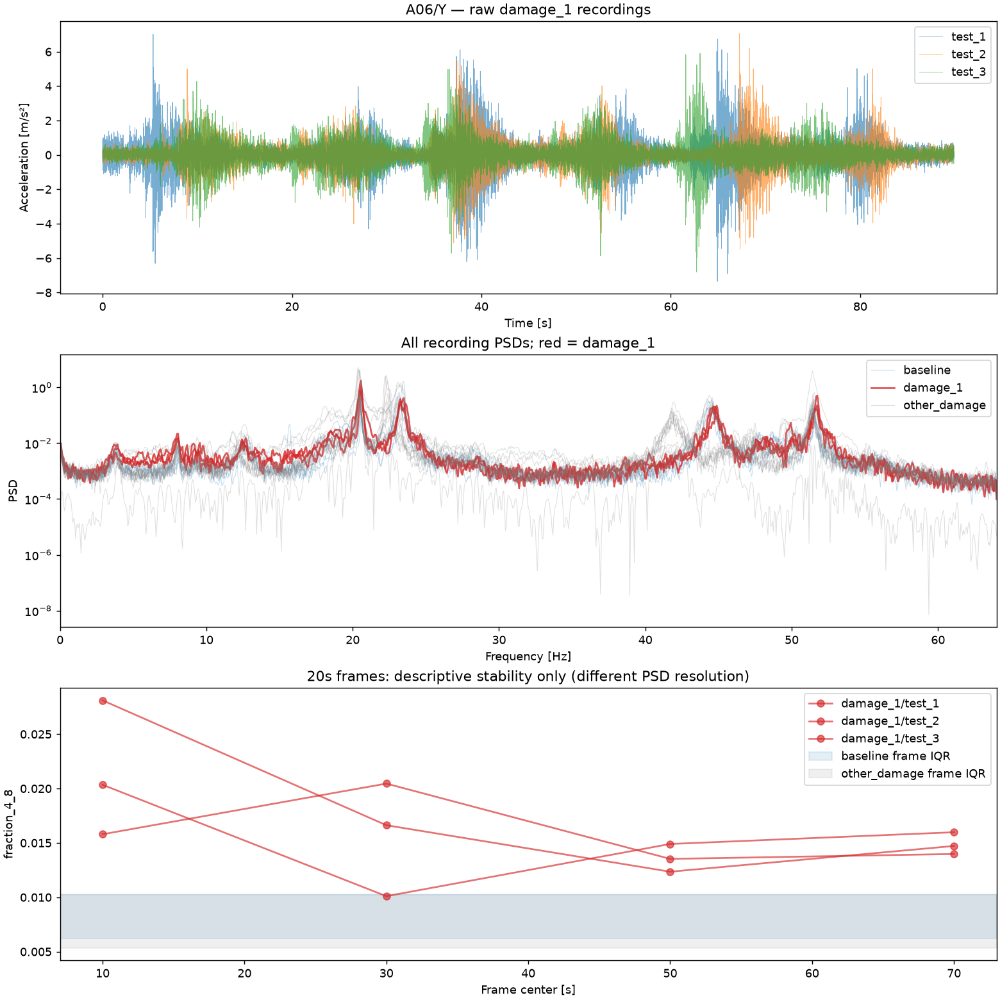

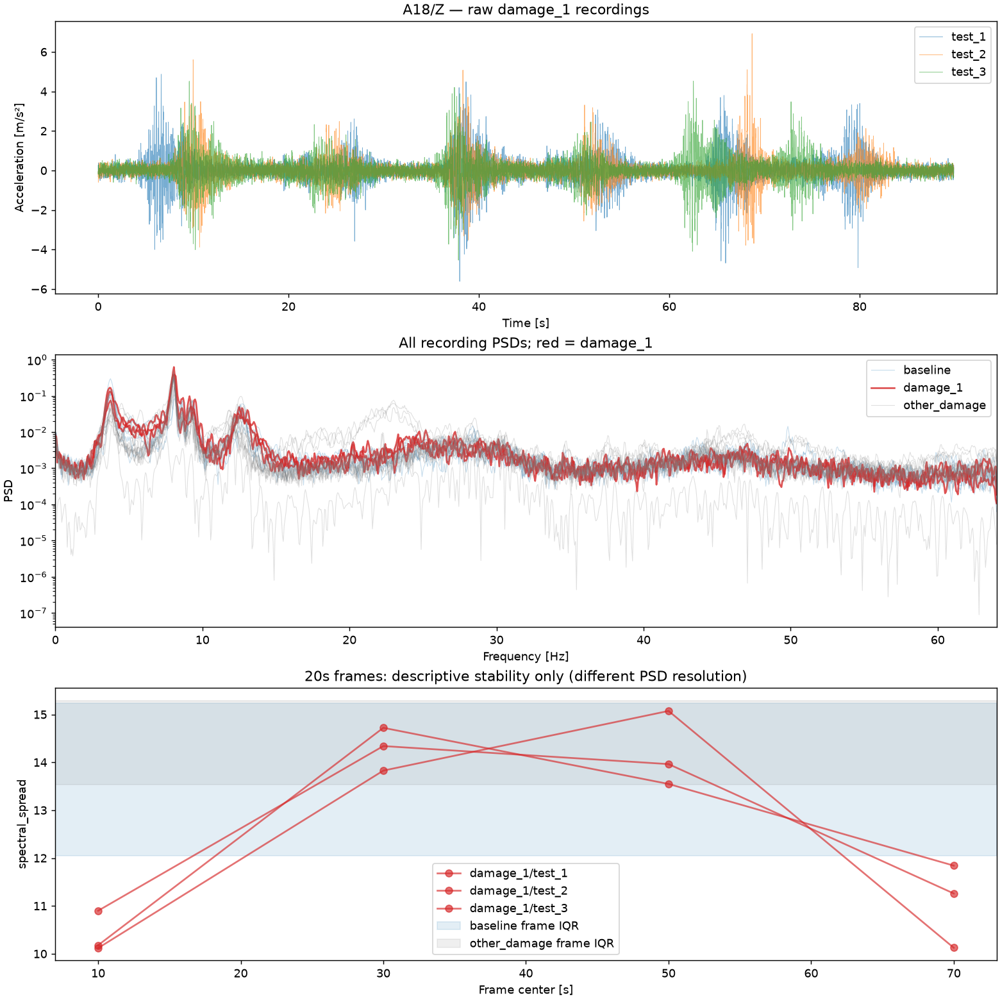

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from check_problem_signals import run_signal_check
signal_check_report=run_signal_check()
for analysis in signal_check_report["analysis"]:
    print(analysis["sensor"],analysis["axis"],analysis["summary"])
from IPython.display import Image,display
for name in ["problem_signal_A06_y.png","problem_signal_A18_z.png"]:
    display(Image(filename=str(ROOT/"outputs"/name)))

## 23. MFCC frame duration and recording summaries

Compare 2/4/8-second frames with 50% overlap. Summarize by mean/std or median/IQR/mean absolute inter-frame change. Each recording is still one sample. Fixed shallow Random Forest, same 20 state-separated allocations, no label-derived feature selection or normalization. Reproduces existing 4s mean/std features and score. Results are exploratory; the best configuration needs new data for confirmation. Different summary families have different feature counts.

[
  {
    "configuration": "4s robust_change",
    "features": 1392,
    "BA_mean": 0.781578947368421,
    "BA_split_SD": 0.11425080810642062,
    "train_BA": 1.0,
    "gap": 0.21916666666666668,
    "damage_AP": 0.9682804695304696,
    "baseline_AP": 0.793234126984127
  },
  {
    "configuration": "2s robust_change",
    "features": 1392,
    "BA_mean": 0.6692982456140351,
    "BA_split_SD": 0.14263087762284152,
    "train_BA": 1.0,
    "gap": 0.3315277777777778,
    "damage_AP": 0.949683177933178,
    "baseline_AP": 0.625536616161616
  },
  {
    "configuration": "4s mean_std",
    "features": 928,
    "BA_mean": 0.6535087719298246,
    "BA_split_SD": 0.07110134782161207,
    "train_BA": 1.0,
    "gap": 0.34708333333333335,
    "damage_AP": 0.9409373774373775,
    "baseline_AP": 0.6112500000000001
  },
  {
    "configuration": "2s mean_std",
    "features": 928,
    "BA_mean": 0.6421052631578947,
    "BA_split_SD": 0.06329176844753488,
    "train_BA": 1.0,
    "gap": 0.35861111111111

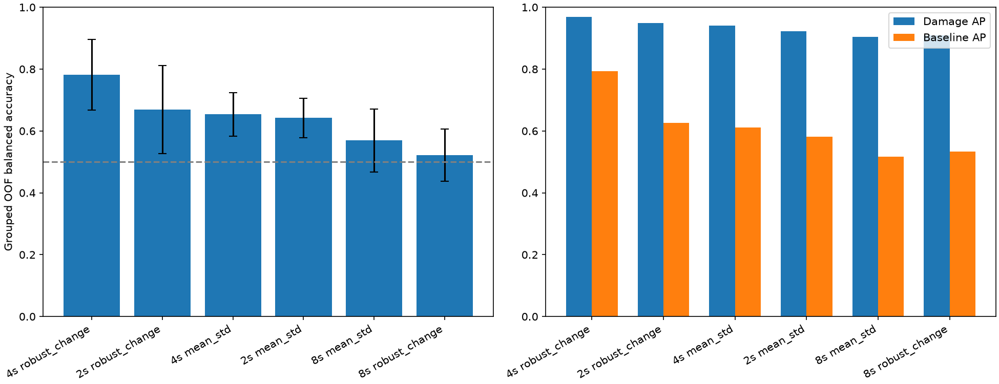

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from mfcc_frame_experiment import run_frame_experiment
frame_report=run_frame_experiment()
show_analysis_table(frame_report["summary"])
print("Frames per recording:",frame_report["frames_per_recording"])
from IPython.display import Image,display
display(Image(filename=str(ROOT/"outputs/mfcc_frame_comparison.png")))

## 24. Improved MFCC audit and model comparison

Independently reconstruct every 4s median/IQR/inter-frame-change row from raw H5 in reverse order; verify labels, absence of metadata inputs, uniqueness, state separation and exactly one held-out prediction per recording per allocation. Confirm scaler means/variances use only training rows. Reproduce every previous Random Forest allocation score. Compare five fixed models on identical features/splits. Passing these checks does not remove post-hoc feature-family selection optimism or establish physical independence or external validity.

{
  "audit": {
    "raw_reconstruction_all_25_passed": true,
    "max_absolute_reconstruction_error": 0.0,
    "labels_aligned": true,
    "one_row_per_recording": true,
    "exact_duplicates": [],
    "label_metadata_not_in_features": true,
    "A14_excluded": true,
    "direct_preprocessing_leakage_found": false,
    "remaining_bias": "4s robust summaries were selected after examining six configurations on these same data. Feature-family/model selection optimism remains. State grouping cannot prove independent excitation conditions or generalization to another bridge.",
    "state_overlap_checks_passed": true,
    "scaler_train_only_checks_passed": true,
    "RF_all_20_scores_reproduced": true
  },
  "summary": [
    {
      "model": "Random Forest",
      "BA_mean": 0.781578947368421,
      "BA_split_SD": 0.11425080810642062,
      "train_BA": 1.0,
      "gap": 0.21916666666666668,
      "damage_AP": 0.9682804695304696,
      "baseline_AP": 0.793234126984127
    },
    {
      "mode

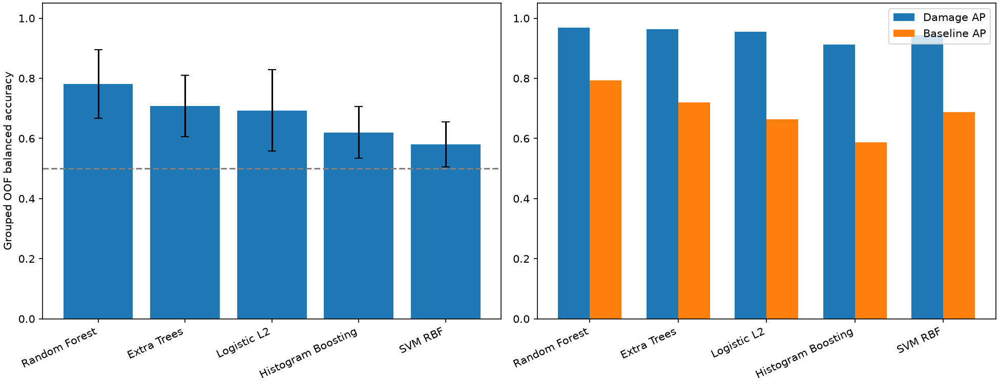

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from audit_compare_robust_mfcc import run_robust_audit
robust_comparison=run_robust_audit()
print(robust_comparison["audit"])
show_analysis_table(robust_comparison["summary"])
from IPython.display import Image,display
display(Image(filename=str(ROOT/"outputs/robust_mfcc_models.png")))

## 25. Improved MFCC: overfit checks and training-only SHAP selection

Shallow Random Forest on 4s MFCC median/IQR/inter-frame-change features. Compare training versus state-held-out scores to diagnose overfitting. For each state-separated training set, rank by mean absolute damage-class TreeSHAP on training rows, refit with 5/10/25/50/100/200 features and evaluate on held-out states. Compare with all 1392 features. Trees require no normalization. Fixed counts are experimental comparisons, not an independently validated choice of best count. SHAP is model attribution, not causality; correlated features may share credit. Forty folds reuse eight states, so split variability is not a confidence interval. See `scripts/shap_feature_selection.py` for implementation.

[
  {
    "features": 5,
    "BA_mean": 0.6813596491228069,
    "BA_split_SD": 0.1392934052254607,
    "paired_BA_change_vs_all": -0.10021929824561404,
    "train_BA": 1.0,
    "gap": 0.3208333333333334,
    "damage_AP": 0.9197409611992946,
    "baseline_AP": 0.6484268046768047
  },
  {
    "features": 10,
    "BA_mean": 0.7234649122807018,
    "BA_split_SD": 0.13202756125659332,
    "paired_BA_change_vs_all": -0.058114035087719326,
    "train_BA": 1.0,
    "gap": 0.27875,
    "damage_AP": 0.9431937244853913,
    "baseline_AP": 0.721445707070707
  },
  {
    "features": 25,
    "BA_mean": 0.7526315789473684,
    "BA_split_SD": 0.12727160304572369,
    "paired_BA_change_vs_all": -0.02894736842105263,
    "train_BA": 1.0,
    "gap": 0.24861111111111117,
    "damage_AP": 0.956211408961409,
    "baseline_AP": 0.745602453102453
  },
  {
    "features": 50,
    "BA_mean": 0.7234649122807018,
    "BA_split_SD": 0.12147994595787903,
    "paired_BA_change_vs_all": -0.0581140350877193,
    "trai

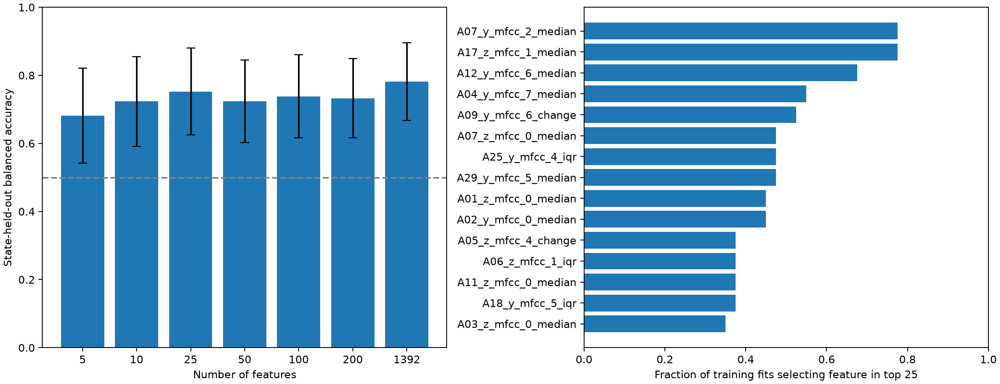

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from robust_shap_selection import run_shap_experiment
shap_selection_report=run_shap_experiment()
show_analysis_table(shap_selection_report["summary"])
show_analysis_table(shap_selection_report["top25_selection_frequency"][:15])
from IPython.display import Image,display
display(Image(filename=str(ROOT/"outputs/robust_shap_selection.png")))

## 26. Stronger forest regularization: training versus grouped validation

Compare six explicit tree settings with all 1392 features or training-only SHAP top 25. Reuse exactly the same state splits and rankings; reproduce both reference scores. Restrict depth, increase minimum leaf samples and vary features considered per split. Report training, grouped validation, AP and gap together: a small gap is not useful if validation collapses. This is exploratory parameter comparison, not tuning against a final test. More trials increase selection optimism.

[
  {
    "configuration": "depth2_leaf4",
    "features": 1392,
    "max_depth": 2,
    "min_samples_leaf": 4,
    "max_features": "sqrt",
    "OOF_BA": 0.8467105263157896,
    "split_SD": 0.04904589451890692,
    "train_BA": 0.9740277777777779,
    "gap": 0.12805555555555556,
    "damage_AP": 0.9668630050505052,
    "baseline_AP": 0.7229861111111111
  },
  {
    "configuration": "depth2_leaf3",
    "features": 1392,
    "max_depth": 2,
    "min_samples_leaf": 3,
    "max_features": "sqrt",
    "OOF_BA": 0.8125,
    "split_SD": 0.10565419873663427,
    "train_BA": 0.9925,
    "gap": 0.18083333333333335,
    "damage_AP": 0.9711280725447393,
    "baseline_AP": 0.7952777777777778
  },
  {
    "configuration": "depth1_leaf3",
    "features": 1392,
    "max_depth": 1,
    "min_samples_leaf": 3,
    "max_features": "sqrt",
    "OOF_BA": 0.8125,
    "split_SD": 0.10565419873663427,
    "train_BA": 0.9925,
    "gap": 0.18083333333333335,
    "damage_AP": 0.9711280725447393,
    "baseline_AP":

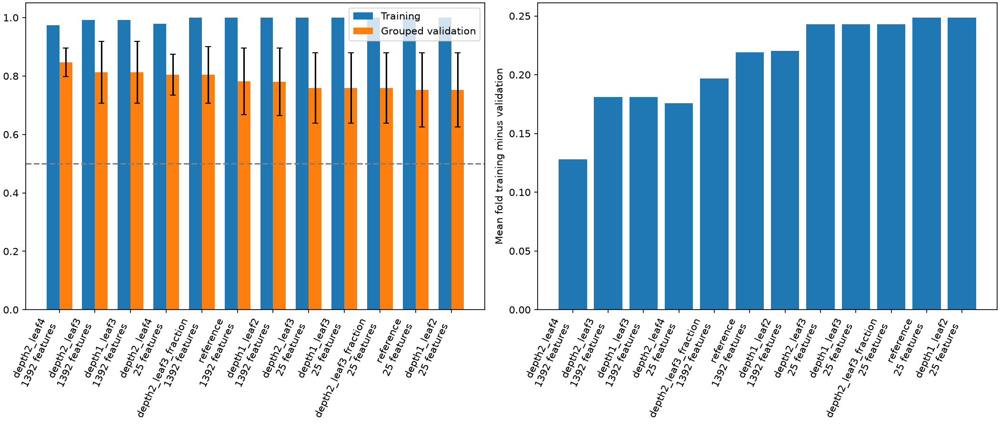

In [ ]:
import sys
if str(ROOT/"scripts") not in sys.path: sys.path.insert(0,str(ROOT/"scripts"))
from regularize_forest import run_regularization
regularization_report=run_regularization()
show_analysis_table(regularization_report["summary"])
from IPython.display import Image,display
display(Image(filename=str(ROOT/"outputs/forest_regularization.png")))

## 27. Audited fixed-duration candidate and MLflow registration

Earlier recordings had class-correlated frame counts (44 baseline versus 43 damage). No frame count was explicitly used as a feature, but summaries could depend on it. Final feature extraction uses exactly 89 seconds and 43 frames in every recording. Reevaluate the fixed forest with state-separated validation. Schema checks reject labels and record IDs, enforce named features and finite inputs, and handle column ordering. This corrects a potential protocol confound; prior 84.7% does not apply to this candidate. MLflow contains a final fit on all 25 records, separately labeled exploratory CV metrics and explicit model-selection bias. It is not a model validated on an untouched external test.

In [ ]:
import json
final_audit=json.loads((ROOT/"outputs/final_pipeline_audit.json").read_text())
registration=json.loads((ROOT/"outputs/mlflow_registration.json").read_text())
print(final_audit["checks"])
show_analysis_table([final_audit["metrics"]])
print(registration)

{
  "run_id": "42e120e5fbd443b4a6831911d57af7e6",
  "experiment_id": "1",
  "tracking_uri": "sqlite:///C:/project_ML/BridgePulse/mlflow.db",
  "model_uri": "models:/m-f6d972ece9dd4c7ea20da37231e4a046",
  "registered_model_name": "BridgePulseDamageRF",
  "registered_model_version": 1,
  "metrics": {
    "grouped_validation_BA_mean": 0.819736842105263,
    "grouped_split_SD": 0.08142907379867882,
    "cv_train_BA_mean": 0.9725000000000001,
    "cv_train_validation_gap": 0.15416666666666665,
    "grouped_damage_AP": 0.9613126796043463,
    "grouped_baseline_AP": 0.7396049783549784,
    "final_fit_training_BA": 0.9736842105263157
  },
  "reload_verified": true
}

## 28. Retrospective grouped holdout, frozen model settings

Seed 2026 assigns three damage states and baseline_2 to holdout. Train a fresh model on remaining states, never use the existing all-record candidate for this evaluation. Fixed 89s features, RF depth 2/min leaf 4/200 trees, threshold .5. No tuning or retries. All records were previously explored; this is not a new independent final test. Run and predictions logged separately in MLflow.

In [ ]:
import json
holdout_report=json.loads((ROOT/"outputs/group_holdout_report.json").read_text())
print("Train:",holdout_report["train_states"],"Holdout:",holdout_report["holdout_states"])
show_analysis_table([{"split":name,**values} for name,values in holdout_report["metrics"].items()])
show_analysis_table([r for r in holdout_report["predictions"] if r["split"]=="holdout"])

{
  "train_states": [
    "baseline_1",
    "damage_2",
    "damage_3",
    "damage_5"
  ],
  "holdout_states": [
    "baseline_2",
    "damage_1",
    "damage_4",
    "damage_6"
  ],
  "split_seed": 2026,
  "parameters_frozen": true,
  "holdout_used_for_fitting": false,
  "metrics": {
    "train": {
      "records": 12,
      "baseline_count": 3,
      "damage_count": 9,
      "balanced_accuracy": 1.0,
      "accuracy": 1.0,
      "damage_AP": 1.0000000000000002,
      "baseline_AP": 1.0,
      "baseline_recall": 1.0,
      "damage_recall": 1.0,
      "confusion_matrix_true_rows_pred_columns_0_1": [
        [
          3,
          0
        ],
        [
          0,
          9
        ]
      ]
    },
    "holdout": {
      "records": 13,
      "baseline_count": 3,
      "damage_count": 10,
      "balanced_accuracy": 0.85,
      "accuracy": 0.7692307692307693,
      "damage_AP": 0.9651515151515152,
      "baseline_AP": 0.7,
      "baseline_recall": 1.0,
      "damage_recall": 0.7,
 

## המשך חקירה
יש 25 הקלטות תאוצה מגשר אחד. לפני אימון יש לאמת את פרוטוקול העירור, האם הנזקים מצטברים והאם מצב הנזק קבוע לאורך ההקלטה. הבדלים חזותיים אינם הוכחת סיבתיות או ביצועי חיזוי. חלוקת אימון וולידציה תיעשה לפי הקלטה שלמה, ובחירת פיצ׳רים בתוך האימון בלבד.
